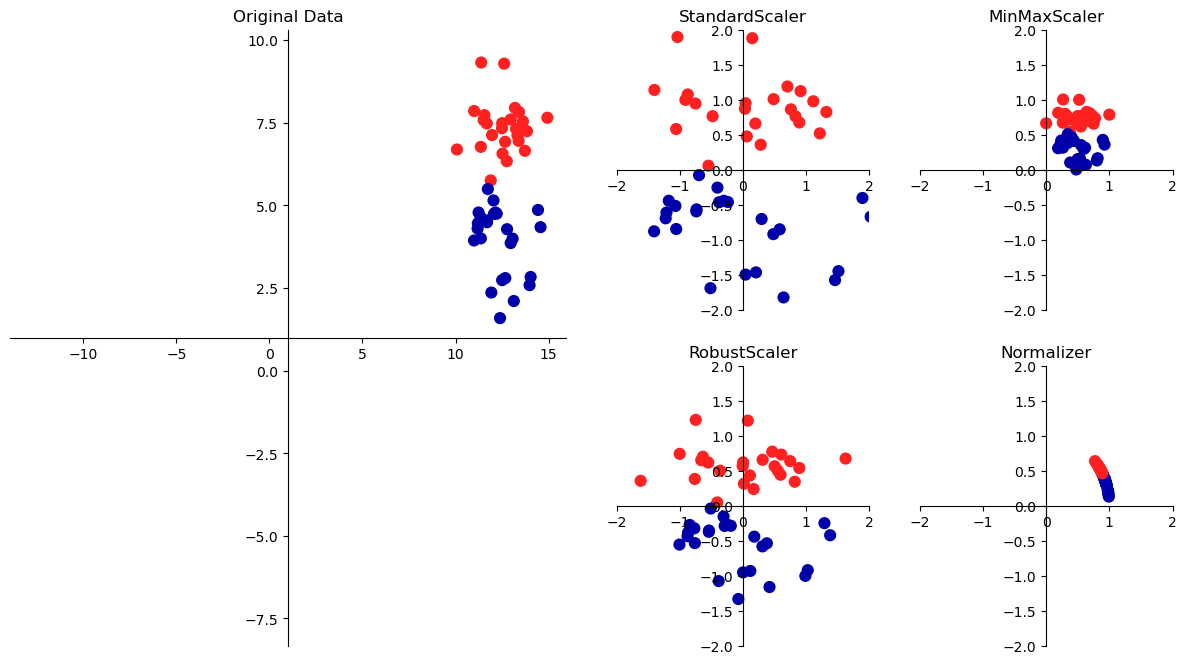

In [2]:
import matplotlib.pyplot as plt
import mglearn

# Generate and display the feature scaling visual
mglearn.plots.plot_scaling()
plt.show()

In [3]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target,
random_state=1)
print(X_train.shape)
print(X_test.shape)

(426, 30)
(143, 30)


In [4]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(X_train)

,feature_range,"(0, ...)"
,copy,True
,clip,False


In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# 1. Load data and split
cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=1
)

# 2. Fit scaler on training data
scaler = MinMaxScaler()
scaler.fit(X_train)

# 3. Transform data
X_train_scaled = scaler.transform(X_train)

# Print dataset properties before and after scaling
print("transformed shape: {}".format(X_train_scaled.shape))
print("per-feature minimum before scaling:\n {}".format(X_train.min(axis=0)))
print("per-feature maximum before scaling:\n {}".format(X_train.max(axis=0)))
print(
    "per-feature minimum after scaling:\n {}".format(
        X_train_scaled.min(axis=0)
    )
)
print(
    "per-feature maximum after scaling:\n {}".format(
        X_train_scaled.max(axis=0)
    )
)

transformed shape: (426, 30)
per-feature minimum before scaling:
 [6.981e+00 9.710e+00 4.379e+01 1.435e+02 5.263e-02 1.938e-02 0.000e+00
 0.000e+00 1.060e-01 5.024e-02 1.153e-01 3.602e-01 7.570e-01 6.802e+00
 1.713e-03 2.252e-03 0.000e+00 0.000e+00 9.539e-03 8.948e-04 7.930e+00
 1.202e+01 5.041e+01 1.852e+02 7.117e-02 2.729e-02 0.000e+00 0.000e+00
 1.566e-01 5.521e-02]
per-feature maximum before scaling:
 [2.811e+01 3.928e+01 1.885e+02 2.501e+03 1.634e-01 2.867e-01 4.268e-01
 2.012e-01 3.040e-01 9.575e-02 2.873e+00 4.885e+00 2.198e+01 5.422e+02
 3.113e-02 1.354e-01 3.960e-01 5.279e-02 6.146e-02 2.984e-02 3.604e+01
 4.954e+01 2.512e+02 4.254e+03 2.226e-01 9.379e-01 1.170e+00 2.910e-01
 5.774e-01 1.486e-01]
per-feature minimum after scaling:
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
per-feature maximum after scaling:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


In [7]:
# transform test data
X_test_scaled = scaler.transform(X_test)
# print test data properties after scaling
print("per-feature minimum after scaling:\n{}".format(X_test_scaled.min(axis=0)))
print("per-feature maximum after scaling:\n{}".format(X_test_scaled.max(axis=0)))

per-feature minimum after scaling:
[ 0.0336031   0.0226581   0.03144219  0.01141039  0.14128374  0.04406704
  0.          0.          0.1540404  -0.00615249 -0.00137796  0.00594501
  0.00430665  0.00079567  0.03919502  0.0112206   0.          0.
 -0.03191387  0.00664013  0.02660975  0.05810235  0.02031974  0.00943767
  0.1094235   0.02637792  0.          0.         -0.00023764 -0.00182032]
per-feature maximum after scaling:
[0.9578778  0.81501522 0.95577362 0.89353128 0.81132075 1.21958701
 0.87956888 0.9333996  0.93232323 1.0371347  0.42669616 0.49765736
 0.44117231 0.28371044 0.48703131 0.73863671 0.76717172 0.62928585
 1.33685792 0.39057253 0.89612238 0.79317697 0.84859804 0.74488793
 0.9154725  1.13188961 1.07008547 0.92371134 1.20532319 1.63068851]


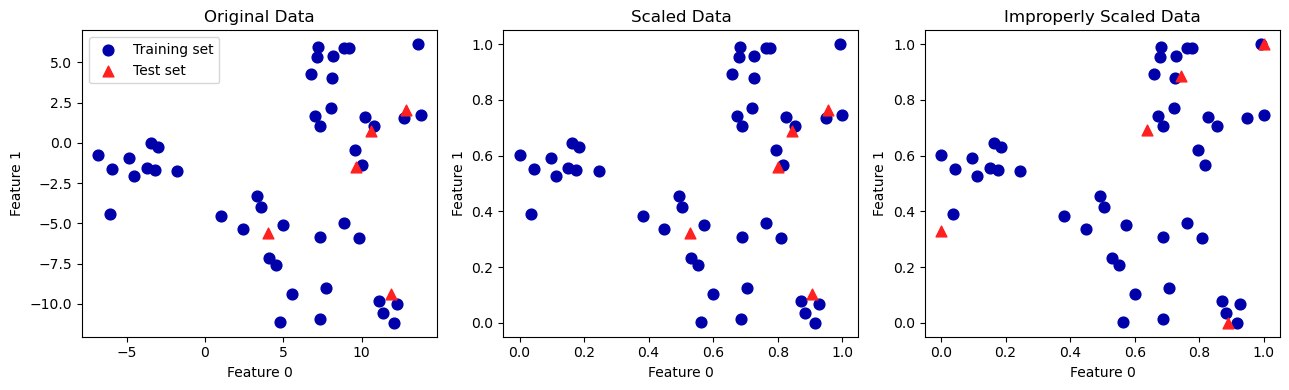

In [9]:
import matplotlib.pyplot as plt
import mglearn
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# 1. Make synthetic data
X, _ = make_blobs(n_samples=50, centers=5, random_state=4, cluster_std=2)

# 2. Split into training and test sets
X_train, X_test = train_test_split(X, random_state=5, test_size=0.1)

# 3. Plot original vs correctly scaled vs improperly scaled data
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# Plot 1: Original Data
axes[0].scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=[mglearn.cm2(0)],
    label="Training set",
    s=60,
)
axes[0].scatter(
    X_test[:, 0],
    X_test[:, 1],
    marker="^",
    c=[mglearn.cm2(1)],
    label="Test set",
    s=60,
)
axes[0].legend(loc="upper left")
axes[0].set_title("Original Data")

# Scale data using MinMaxScaler fitted ONLY on training data
scaler = MinMaxScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Plot 2: Properly Scaled Data
axes[1].scatter(
    X_train_scaled[:, 0],
    X_train_scaled[:, 1],
    c=[mglearn.cm2(0)],
    label="Training set",
    s=60,
)
axes[1].scatter(
    X_test_scaled[:, 0],
    X_test_scaled[:, 1],
    marker="^",
    c=[mglearn.cm2(1)],
    label="Test set",
    s=60,
)
axes[1].set_title("Scaled Data")

# Rescale test set separately (DO NOT DO THIS)
test_scaler = MinMaxScaler()
test_scaler.fit(X_test)
X_test_scaled_badly = test_scaler.transform(X_test)

# Plot 3: Improperly Scaled Data
axes[2].scatter(
    X_train_scaled[:, 0],
    X_train_scaled[:, 1],
    c=[mglearn.cm2(0)],
    label="training set",
    s=60,
)
axes[2].scatter(
    X_test_scaled_badly[:, 0],
    X_test_scaled_badly[:, 1],
    marker="^",
    c=[mglearn.cm2(1)],
    label="test set",
    s=60,
)
axes[2].set_title("Improperly Scaled Data")

for ax in axes:
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")

plt.tight_layout()
plt.show()

In [10]:
#from sklearn.preprocessing import StandardScaler
#scaler = StandardScaler()
# calling fit and transform in sequence (using method chaining)
#X_scaled = scaler.fit(X).transform(X)
# same result, but more efficient computation
#X_scaled_d = scaler.fit_transform(X)

In [11]:
from sklearn.svm import SVC
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target,
random_state=0)
svm = SVC(C=100)
svm.fit(X_train, y_train)
print("Test set accuracy: {:.2f}".format(svm.score(X_test, y_test)))

Test set accuracy: 0.94


In [12]:
# preprocessing using 0-1 scaling
scaler = MinMaxScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
# learning an SVM on the scaled training data
svm.fit(X_train_scaled, y_train)
# scoring on the scaled test set
print("Scaled test set accuracy: {:.2f}".format(
svm.score(X_test_scaled, y_test)))

Scaled test set accuracy: 0.97


In [13]:
# preprocessing using zero mean and unit variance scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
# learning an SVM on the scaled training data
svm.fit(X_train_scaled, y_train)
# scoring on the scaled test set
print("SVM test accuracy: {:.2f}".format(svm.score(X_test_scaled, y_test)))

SVM test accuracy: 0.96


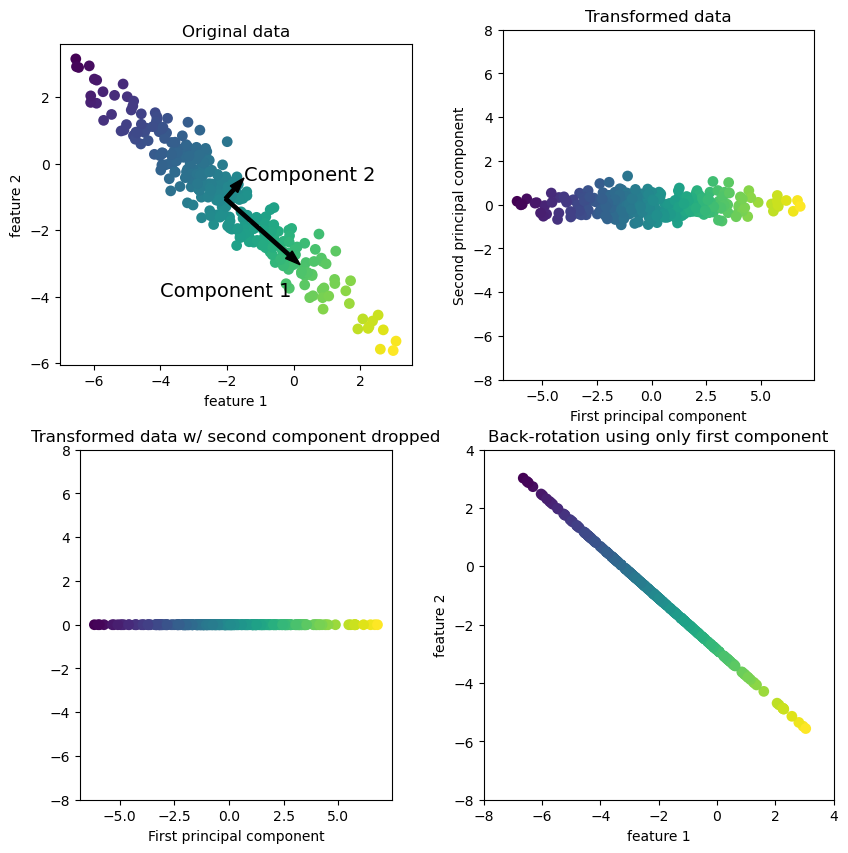

In [14]:
mglearn.plots.plot_pca_illustration()

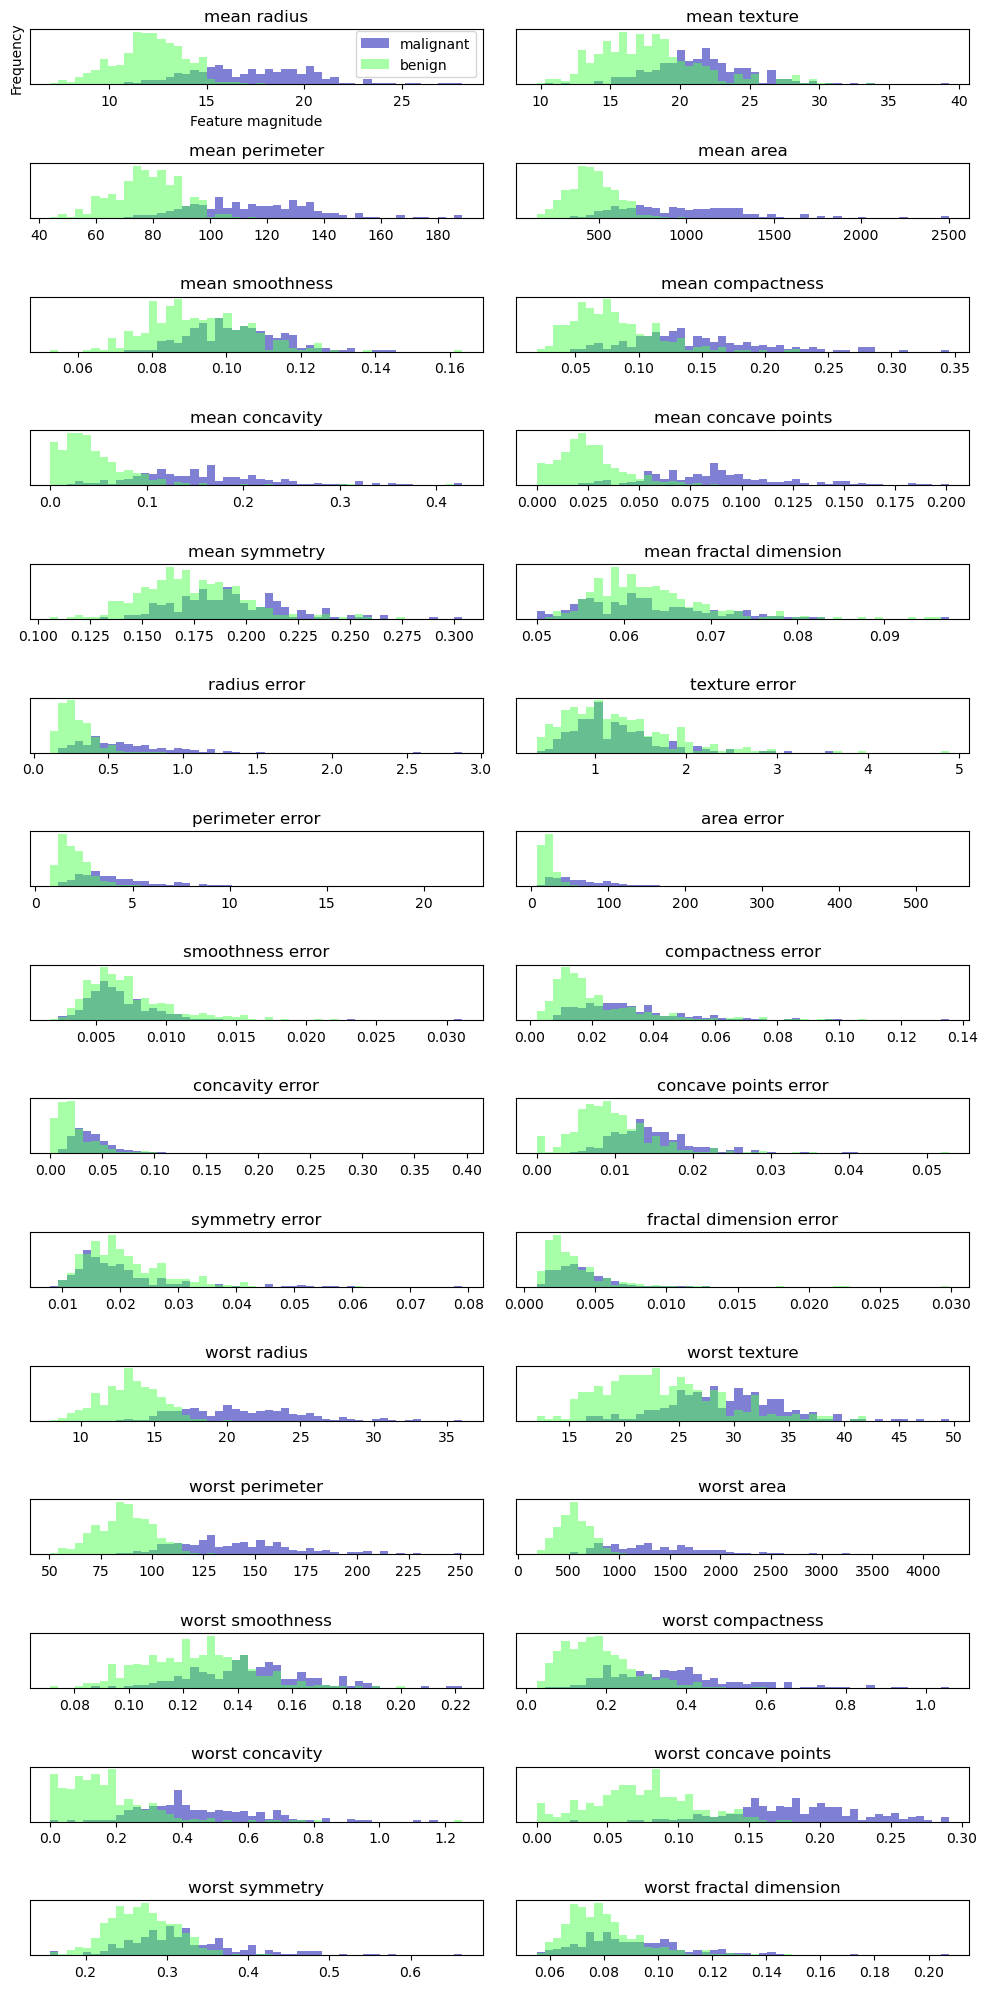

In [16]:
import matplotlib.pyplot as plt
import mglearn
import numpy as np
from sklearn.datasets import load_breast_cancer

# 1. Load dataset
cancer = load_breast_cancer()

# 2. Split data by class
malignant = cancer.data[cancer.target == 0]
benign = cancer.data[cancer.target == 1]

# 3. Create histograms for all 30 features
fig, axes = plt.subplots(15, 2, figsize=(10, 20))
ax = axes.ravel()

for i in range(30):
    _, bins = np.histogram(cancer.data[:, i], bins=50)
    ax[i].hist(malignant[:, i], bins=bins, color=mglearn.cm3(0), alpha=0.5)
    ax[i].hist(benign[:, i], bins=bins, color=mglearn.cm3(2), alpha=0.5)
    ax[i].set_title(cancer.feature_names[i])
    ax[i].set_yticks(())

ax[0].set_xlabel("Feature magnitude")
ax[0].set_ylabel("Frequency")
ax[0].legend(["malignant", "benign"], loc="best")

fig.tight_layout()
plt.show()

In [18]:
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer()
scaler = StandardScaler()
scaler.fit(cancer.data)
X_scaled = scaler.transform(cancer.data)
from sklearn.decomposition import PCA
# keep the first two principal components of the data
pca = PCA(n_components=2)
# fit PCA model to breast cancer data
pca.fit(X_scaled)
# transform data onto the first two principal components
X_pca = pca.transform(X_scaled)
print("Original shape: {}".format(str(X_scaled.shape)))
print("Reduced shape: {}".format(str(X_pca.shape)))

Original shape: (569, 30)
Reduced shape: (569, 2)


Text(0, 0.5, 'Second principal component')

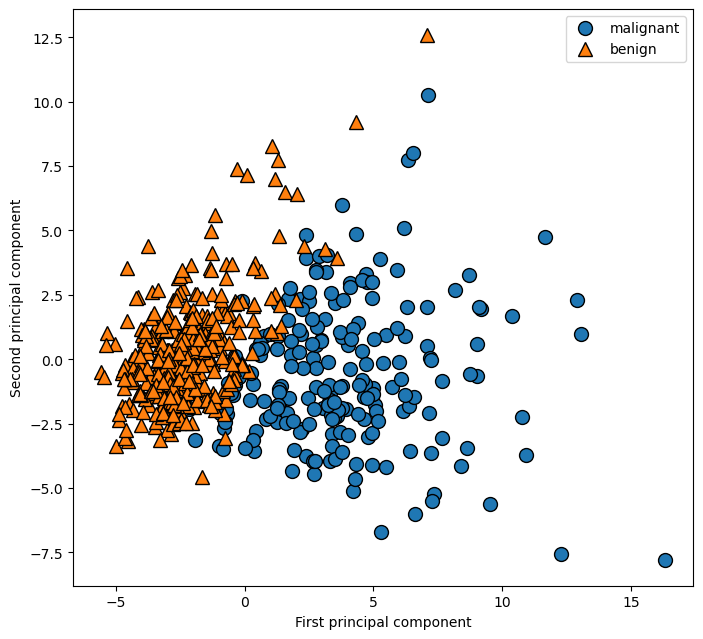

In [19]:
# plot first vs. second principal component, colored by class
plt.figure(figsize=(8, 8))
mglearn.discrete_scatter(X_pca[:, 0], X_pca[:, 1], cancer.target)
plt.legend(cancer.target_names, loc="best")
plt.gca().set_aspect("equal")
plt.xlabel("First principal component")
plt.ylabel("Second principal component")

In [20]:
print("PCA component shape: {}".format(pca.components_.shape))

PCA component shape: (2, 30)


In [21]:
print("PCA components:\n{}".format(pca.components_))

PCA components:
[[ 0.21890244  0.10372458  0.22753729  0.22099499  0.14258969  0.23928535
   0.25840048  0.26085376  0.13816696  0.06436335  0.20597878  0.01742803
   0.21132592  0.20286964  0.01453145  0.17039345  0.15358979  0.1834174
   0.04249842  0.10256832  0.22799663  0.10446933  0.23663968  0.22487053
   0.12795256  0.21009588  0.22876753  0.25088597  0.12290456  0.13178394]
 [-0.23385713 -0.05970609 -0.21518136 -0.23107671  0.18611302  0.15189161
   0.06016536 -0.0347675   0.19034877  0.36657547 -0.10555215  0.08997968
  -0.08945723 -0.15229263  0.20443045  0.2327159   0.19720728  0.13032156
   0.183848    0.28009203 -0.21986638 -0.0454673  -0.19987843 -0.21935186
   0.17230435  0.14359317  0.09796411 -0.00825724  0.14188335  0.27533947]]


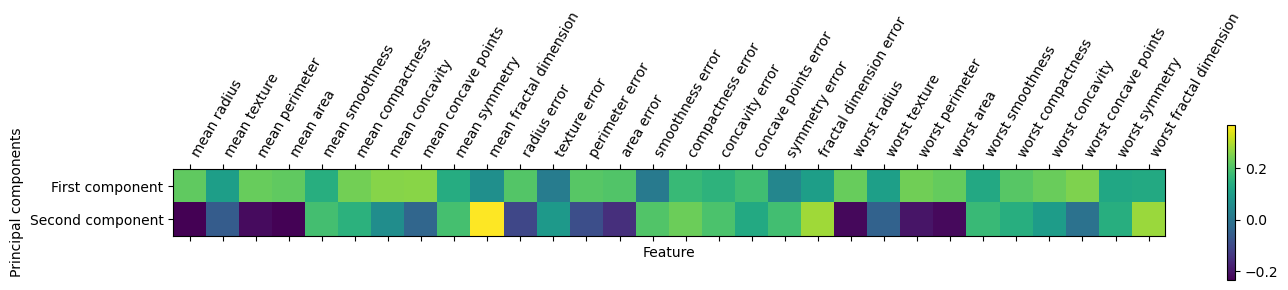

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Load data and standardize features
cancer = load_breast_cancer()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cancer.data)

# 2. Fit PCA with 2 components
pca = PCA(n_components=2)
pca.fit(X_scaled)

# 3. Plot component heatmap
plt.matshow(pca.components_, cmap="viridis")
plt.yticks([0, 1], ["First component", "Second component"])
plt.colorbar()
plt.xticks(
    range(len(cancer.feature_names)),
    cancer.feature_names,
    rotation=60,
    ha="left",
)
plt.xlabel("Feature")
plt.ylabel("Principal components")

plt.show()

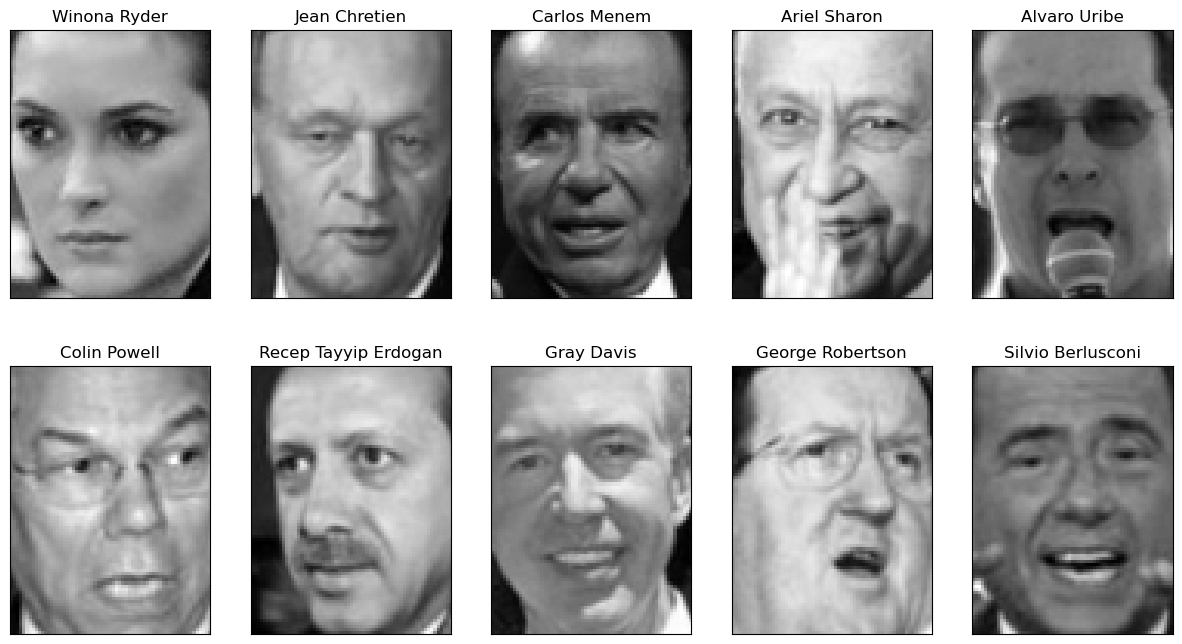

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_lfw_people

# 1. Fetch LFW dataset
people = fetch_lfw_people(min_faces_per_person=20, resize=0.7)
image_shape = people.images[0].shape

# 2. Setup 2x5 subplot grid
fig, axes = plt.subplots(
    2, 5, figsize=(15, 8), subplot_kw={"xticks": (), "yticks": ()}
)

# 3. Iterate and plot face samples
for target, image, ax in zip(people.target, people.images, axes.ravel()):
    ax.imshow(image, cmap="gray")
    ax.set_title(people.target_names[target])

plt.show()

In [3]:
print("people.images.shape: {}".format(people.images.shape))
print("Number of classes: {}".format(len(people.target_names)))

people.images.shape: (3023, 87, 65)
Number of classes: 62


In [5]:
import numpy as np
from sklearn.datasets import fetch_lfw_people

# 1. Fetch LFW dataset
people = fetch_lfw_people(min_faces_per_person=20, resize=0.7)

# 2. Count target occurrences
counts = np.bincount(people.target)

# 3. Print counts next to target names in 3 columns
for i, (count, name) in enumerate(zip(counts, people.target_names)):
    print("{0:25} {1:3}".format(name, count), end=" ")
    if (i + 1) % 3 == 0:
        print()

Alejandro Toledo           39 Alvaro Uribe               35 Amelie Mauresmo            21 
Andre Agassi               36 Angelina Jolie             20 Ariel Sharon               77 
Arnold Schwarzenegger      42 Atal Bihari Vajpayee       24 Bill Clinton               29 
Carlos Menem               21 Colin Powell              236 David Beckham              31 
Donald Rumsfeld           121 George Robertson           22 George W Bush             530 
Gerhard Schroeder         109 Gloria Macapagal Arroyo    44 Gray Davis                 26 
Guillermo Coria            30 Hamid Karzai               22 Hans Blix                  39 
Hugo Chavez                71 Igor Ivanov                20 Jack Straw                 28 
Jacques Chirac             52 Jean Chretien              55 Jennifer Aniston           21 
Jennifer Capriati          42 Jennifer Lopez             21 Jeremy Greenstock          24 
Jiang Zemin                20 John Ashcroft              53 John Negroponte            31 

In [7]:
import numpy as np
from sklearn.datasets import fetch_lfw_people

# 1. Fetch LFW dataset
people = fetch_lfw_people(min_faces_per_person=20, resize=0.7)

# 2. Select up to 50 images per person
mask = np.zeros(people.target.shape, dtype=bool)  # Use standard bool
for target in np.unique(people.target):
    mask[np.where(people.target == target)[0][:50]] = True

X_people = people.data[mask]
y_people = people.target[mask]

# 3. Scale pixel values to [0, 1] for numerical stability
X_people = X_people / 255.0

print("Subset shape:", X_people.shape)

Subset shape: (2063, 5655)


In [9]:
import numpy as np
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# 1. Prepare LFW subset (50 images max per person)
people = fetch_lfw_people(min_faces_per_person=20, resize=0.7)
mask = np.zeros(people.target.shape, dtype=bool)
for target in np.unique(people.target):
    mask[np.where(people.target == target)[0][:50]] = True

X_people = people.data[mask] / 255.0
y_people = people.target[mask]

# 2. Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_people, y_people, stratify=y_people, random_state=0
)

# 3. Fit 1-NN model and compute accuracy
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)

print("Test set score of 1-nn: {:.2f}".format(knn.score(X_test, y_test)))

Test set score of 1-nn: 0.22


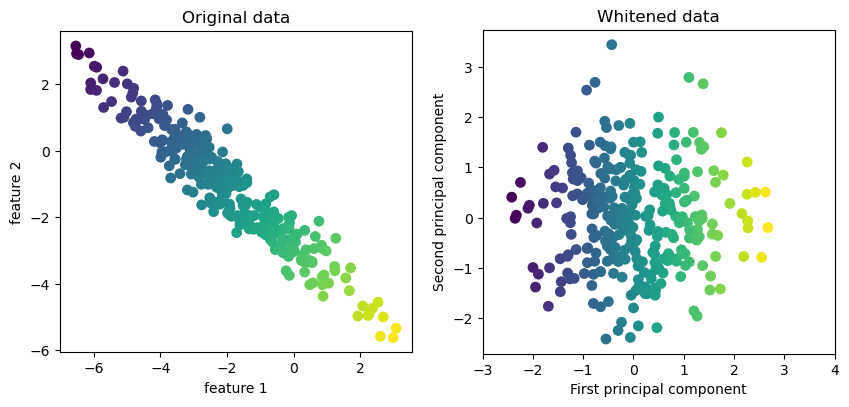

In [11]:
import matplotlib.pyplot as plt
import mglearn

# Generate and render the PCA whitening visual
mglearn.plots.plot_pca_whitening()
plt.show()

In [12]:
pca = PCA(n_components=100, whiten=True, random_state=0).fit(X_train)
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)
print("X_train_pca.shape: {}".format(X_train_pca.shape))

X_train_pca.shape: (1547, 100)


In [13]:
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train_pca, y_train)
print("Test set accuracy: {:.2f}".format(knn.score(X_test_pca, y_test)))

Test set accuracy: 0.30


In [14]:
print("pca.components_.shape: {}".format(pca.components_.shape))

pca.components_.shape: (100, 5655)


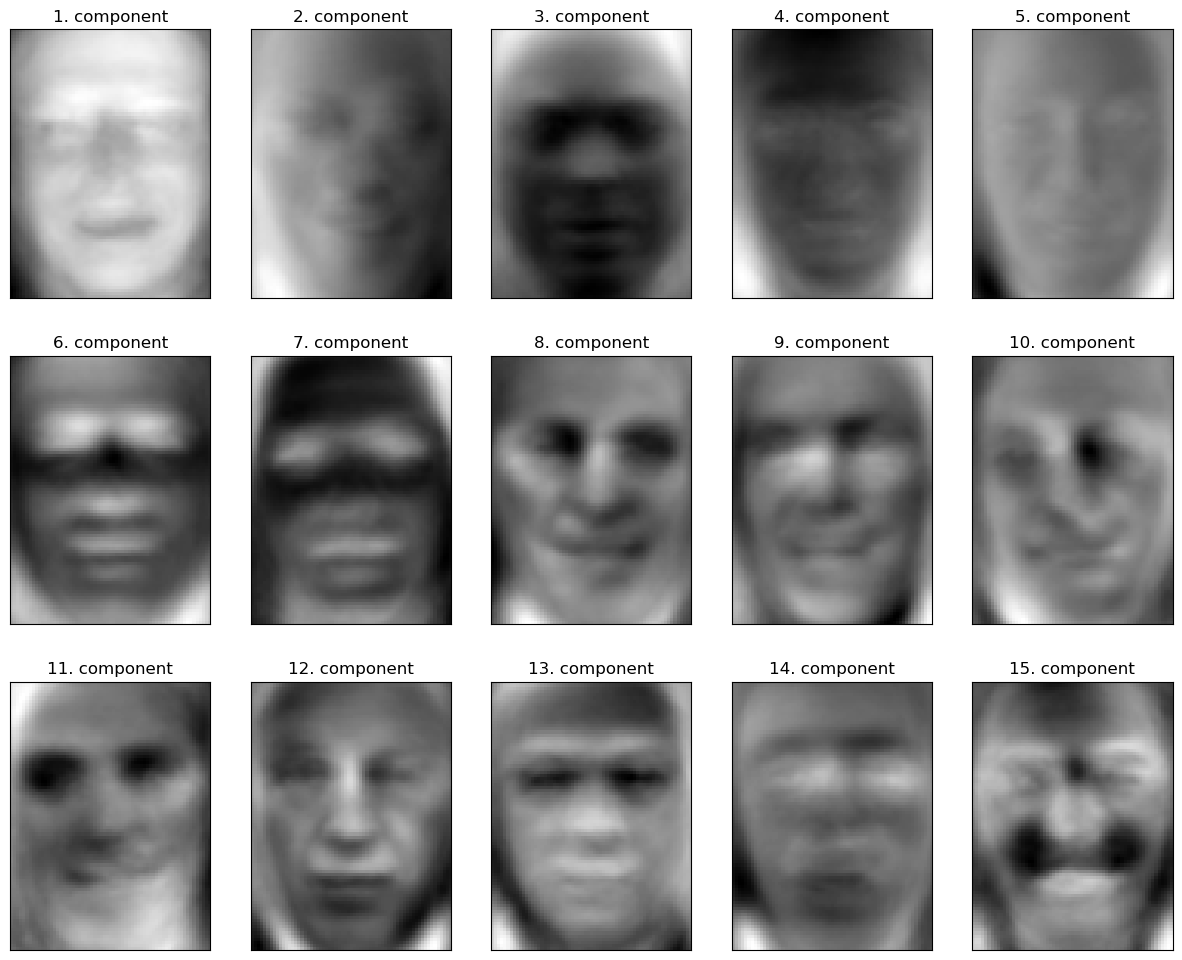

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_lfw_people
from sklearn.decomposition import PCA

# 1. Load LFW dataset subset
people = fetch_lfw_people(min_faces_per_person=20, resize=0.7)
image_shape = people.images[0].shape

mask = np.zeros(people.target.shape, dtype=bool)
for target in np.unique(people.target):
    mask[np.where(people.target == target)[0][:50]] = True

X_people = people.data[mask] / 255.0

# 2. Fit PCA with 15 components
pca = PCA(n_components=15, whiten=True, random_state=0)
pca.fit(X_people)

# 3. Plot the first 15 principal components (Eigenfaces)
fig, axes = plt.subplots(
    3, 5, figsize=(15, 12), subplot_kw={"xticks": (), "yticks": ()}
)

for i, (component, ax) in enumerate(zip(pca.components_, axes.ravel())):
    ax.imshow(component.reshape(image_shape), cmap="gray")
    ax.set_title(f"{i + 1}. component")

plt.show()

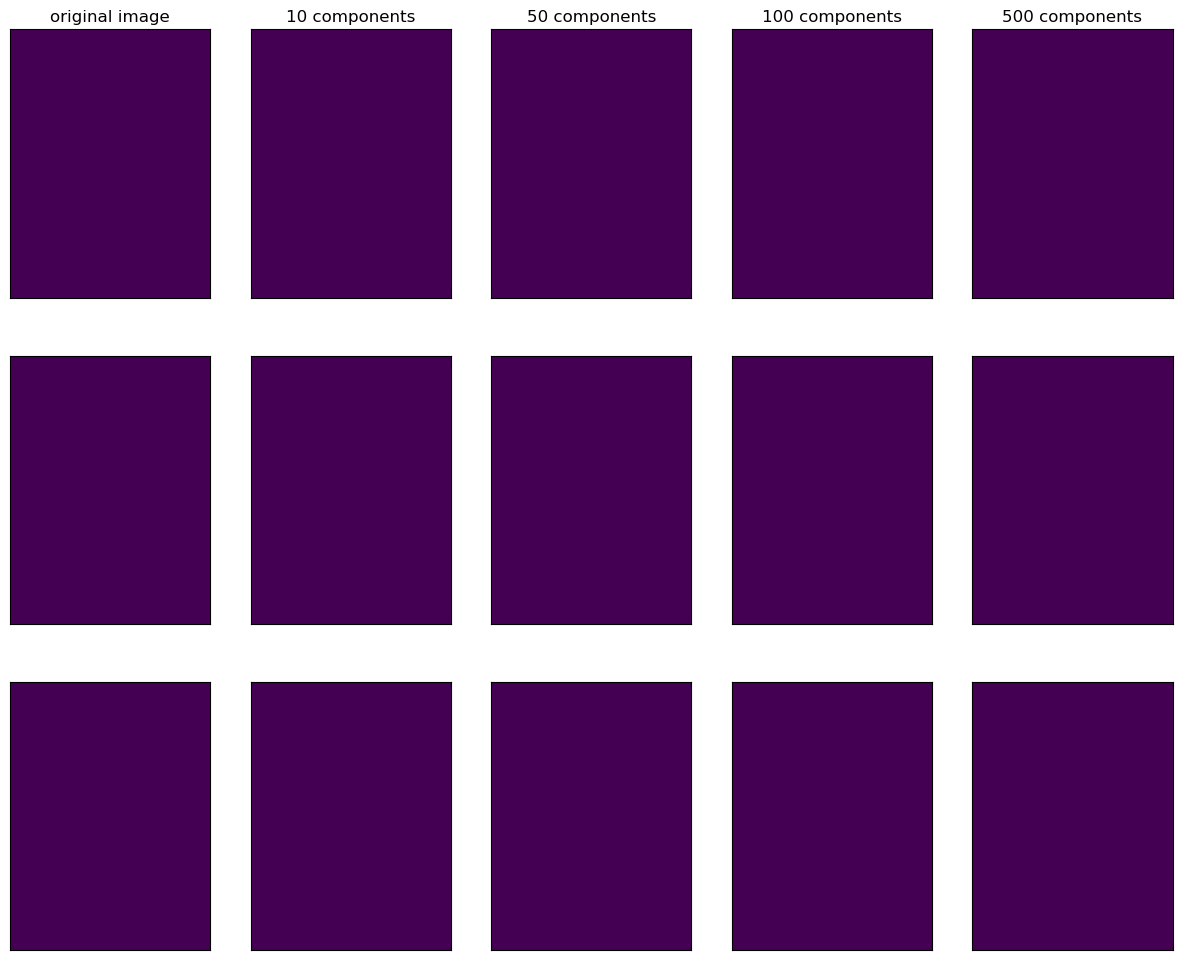

In [17]:
mglearn.plots.plot_pca_faces(X_train, X_test, image_shape)

Text(0, 0.5, 'Second principal component')

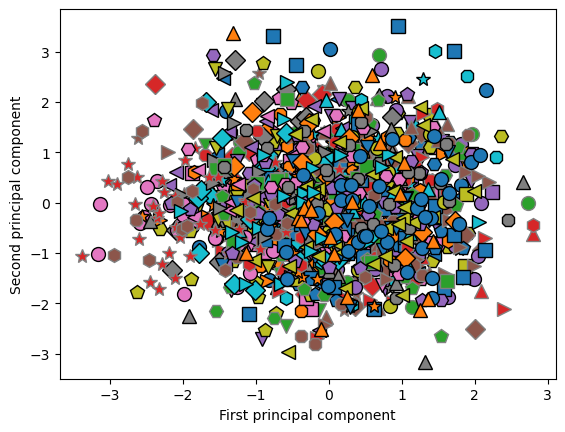

In [18]:
mglearn.discrete_scatter(X_train_pca[:, 0], X_train_pca[:, 1], y_train)
plt.xlabel("First principal component")
plt.ylabel("Second principal component")

/opt/anaconda3/lib/python3.13/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


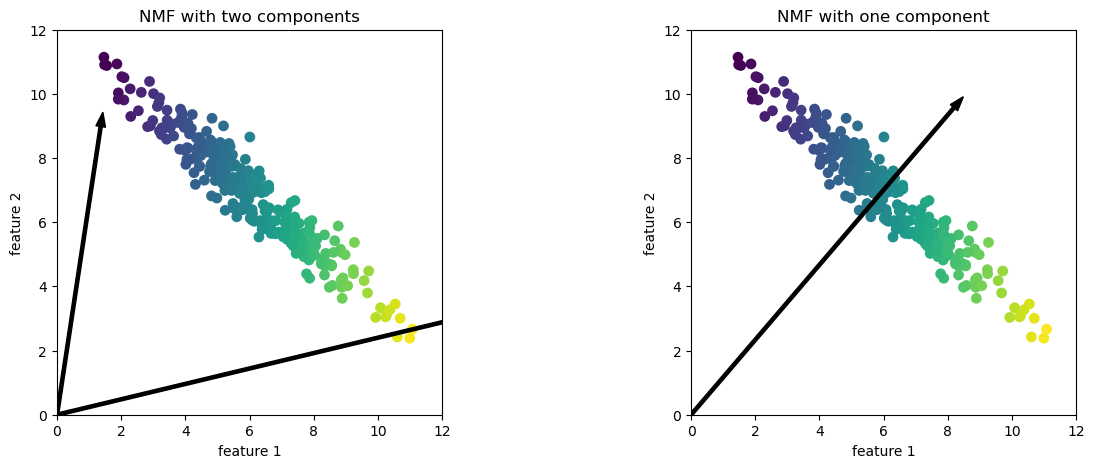

In [19]:
mglearn.plots.plot_nmf_illustration()

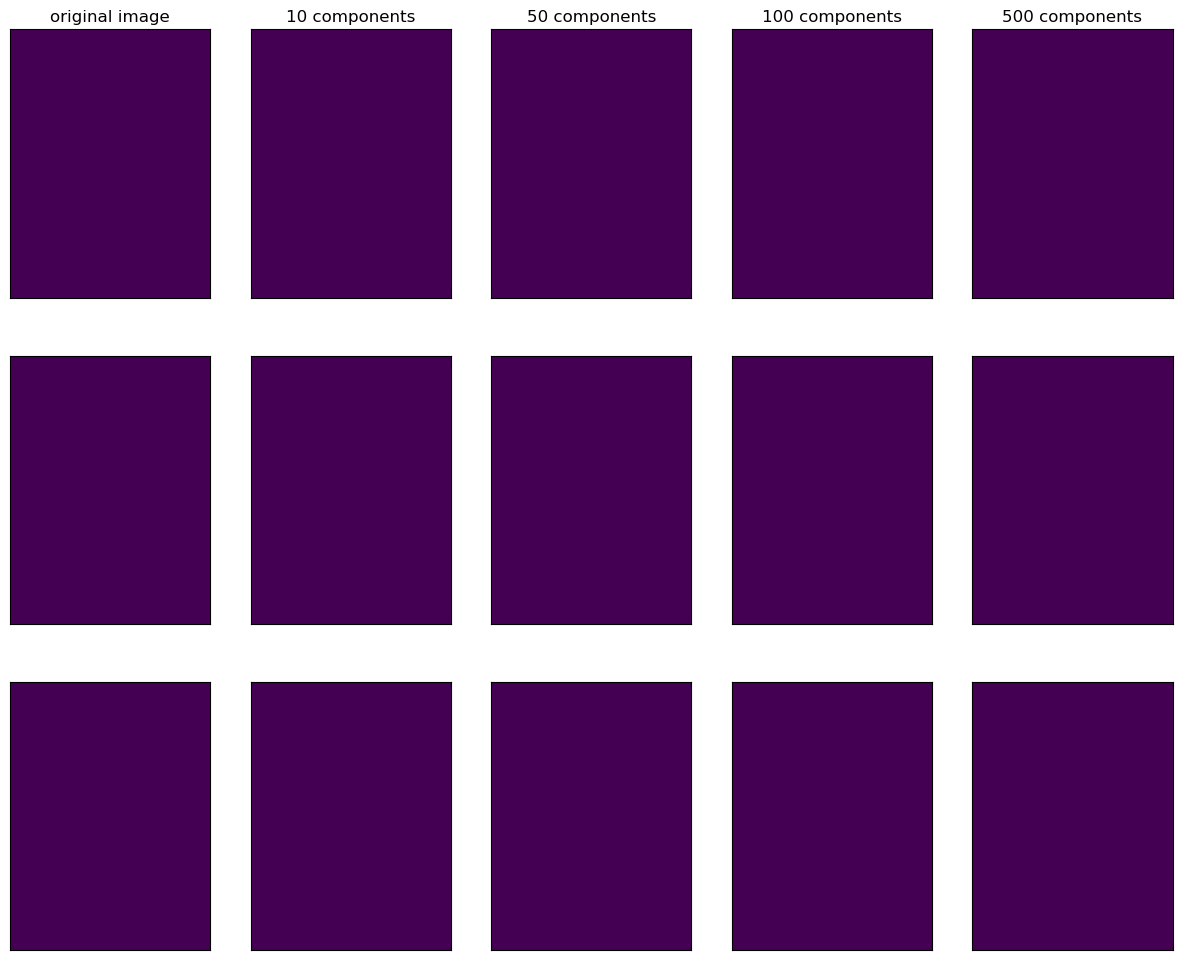

In [1]:
import matplotlib.pyplot as plt
import mglearn
import numpy as np
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split

# 1. Fetch LFW dataset & create subset
people = fetch_lfw_people(min_faces_per_person=20, resize=0.7)
image_shape = people.images[0].shape

mask = np.zeros(people.target.shape, dtype=bool)
for target in np.unique(people.target):
    mask[np.where(people.target == target)[0][:50]] = True

X_people = people.data[mask] / 255.0
y_people = people.target[mask]

# 2. Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X_people, y_people, stratify=y_people, random_state=0
)

# 3. Plot NMF face reconstructions
mglearn.plots.plot_nmf_faces(X_train, X_test, image_shape)
plt.show()

In [4]:
from sklearn.decomposition import NMF
import numpy as np
import matplotlib.pyplot as plt

# Create NMF model
nmf = NMF(n_components=15, random_state=42)

# Transform training data
X_train_nmf = nmf.fit_transform(X_train)

# Image shape
image_shape = X_train.shape[1:]

print("X_train shape:", X_train.shape)
print("X_train_nmf shape:", X_train_nmf.shape)

X_train shape: (1547, 5655)
X_train_nmf shape: (1547, 15)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


In [6]:
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split

people = fetch_lfw_people(min_faces_per_person=20, resize=0.7)

X = people.images
y = people.target

image_shape = X.shape[1:]

X_train, X_test, y_train, y_test = train_test_split(
    X.reshape(len(X), -1),
    y,
    test_size=0.25,
    random_state=42
)

print(X_train.shape)
print(image_shape)

(2267, 5655)
(87, 65)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


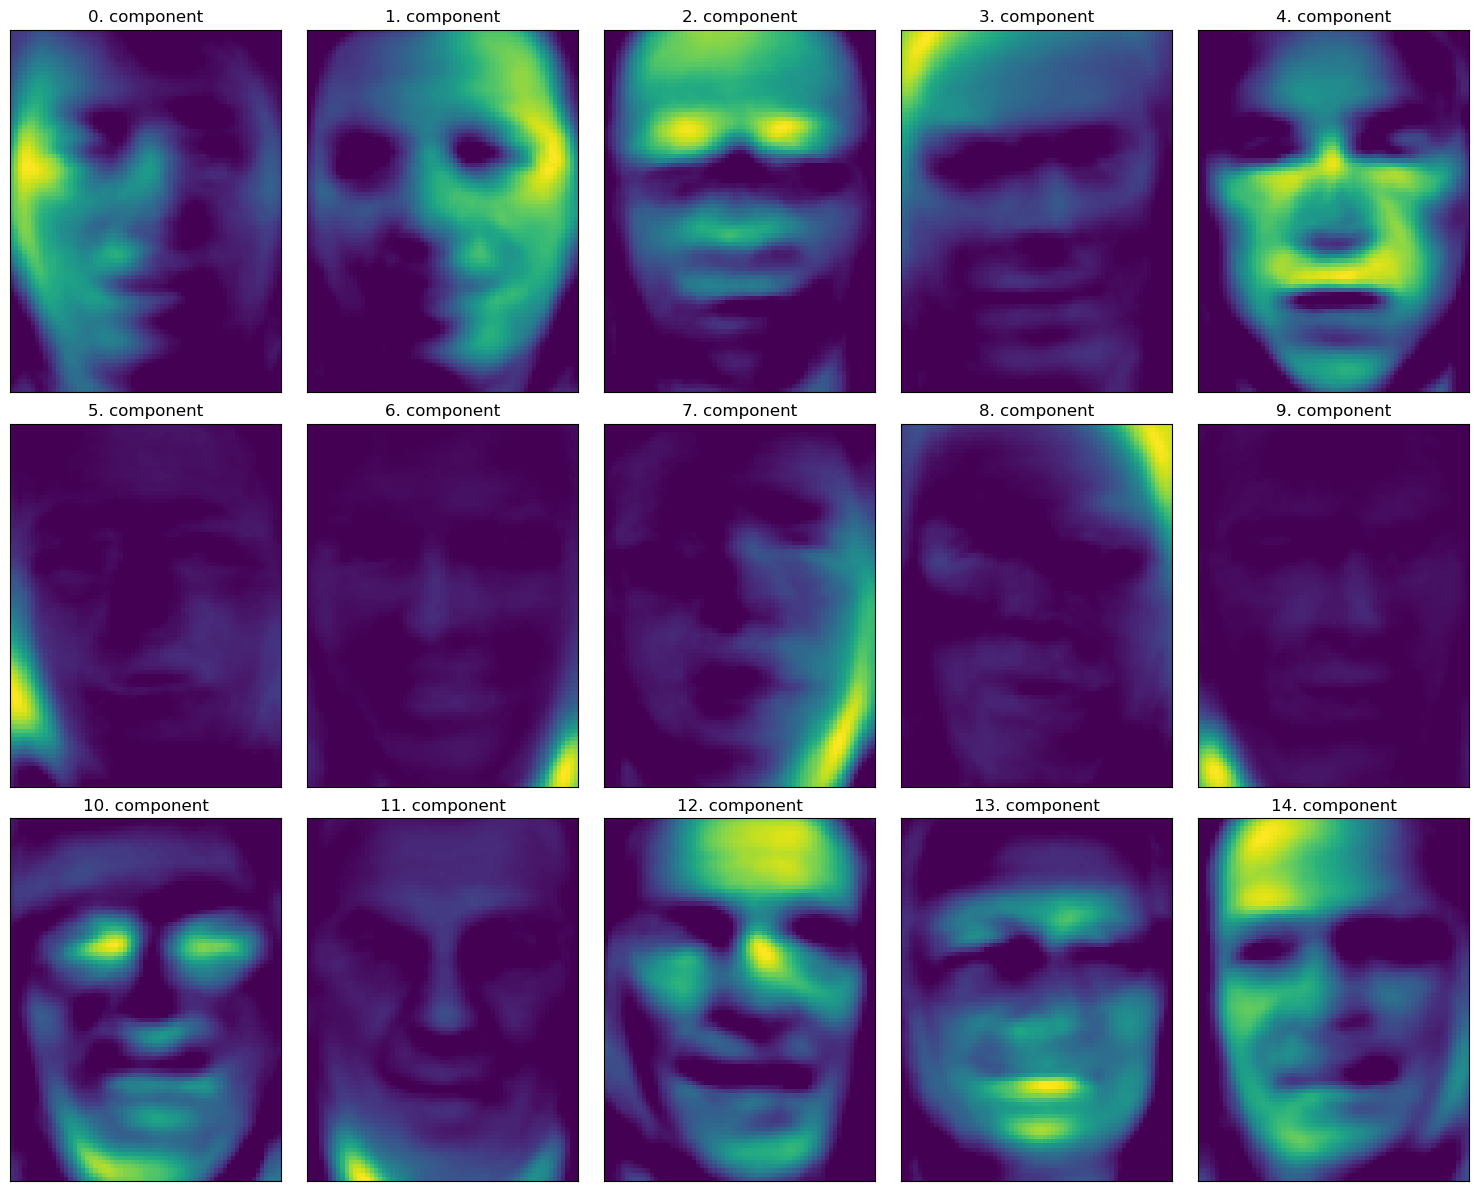

In [8]:
import matplotlib.pyplot as plt
from sklearn.decomposition import NMF

# Fit NMF and transform training data in one step
nmf = NMF(n_components=15, random_state=0)
X_train_nmf = nmf.fit_transform(X_train)
X_test_nmf = nmf.transform(X_test)

# Plot components
fig, axes = plt.subplots(
    3, 5, figsize=(15, 12), subplot_kw={"xticks": (), "yticks": ()}
)

for i, (component, ax) in enumerate(zip(nmf.components_, axes.ravel())):
    ax.imshow(component.reshape(image_shape), cmap="viridis")
    ax.set_title(f"{i}. component")

plt.tight_layout()
plt.show()

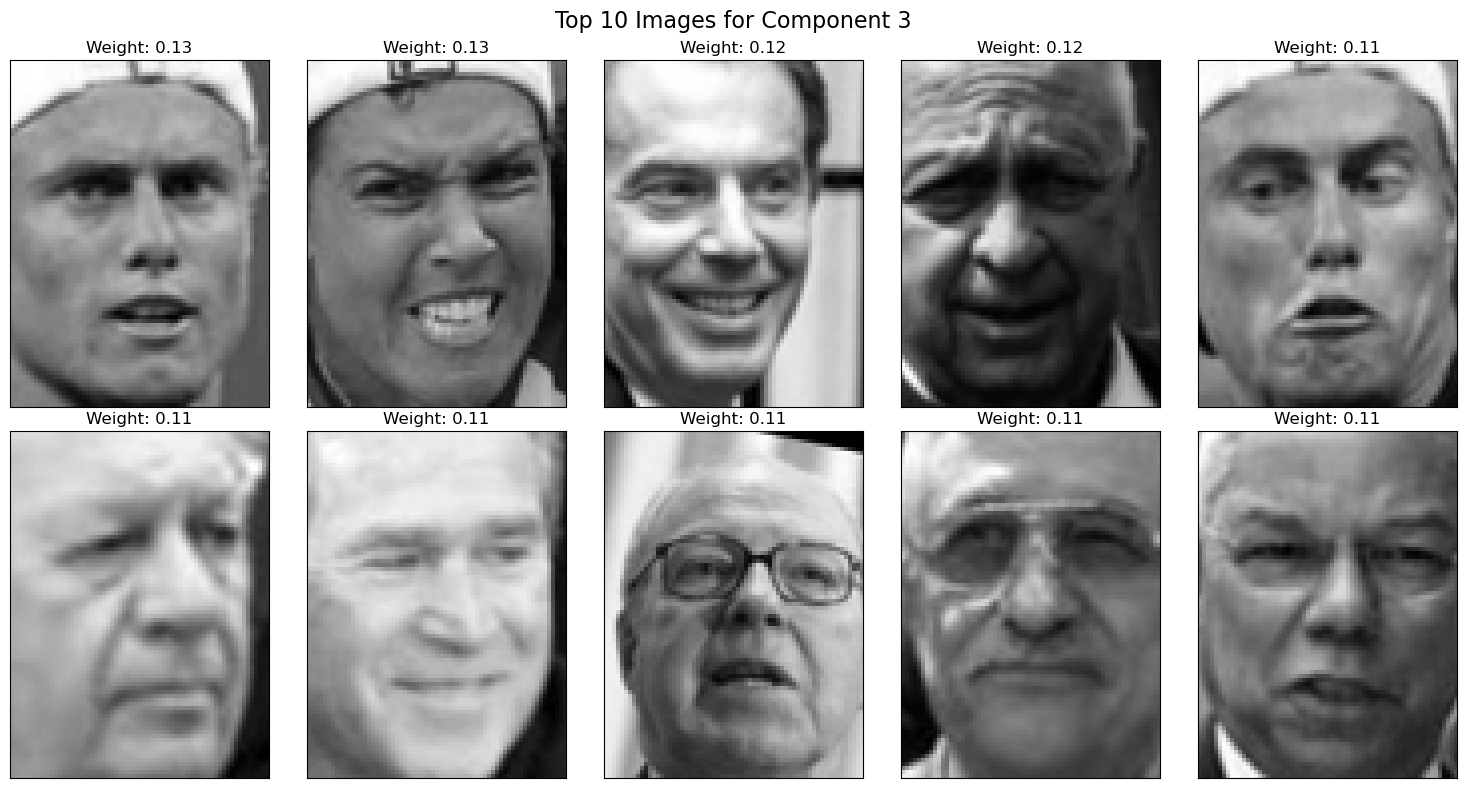

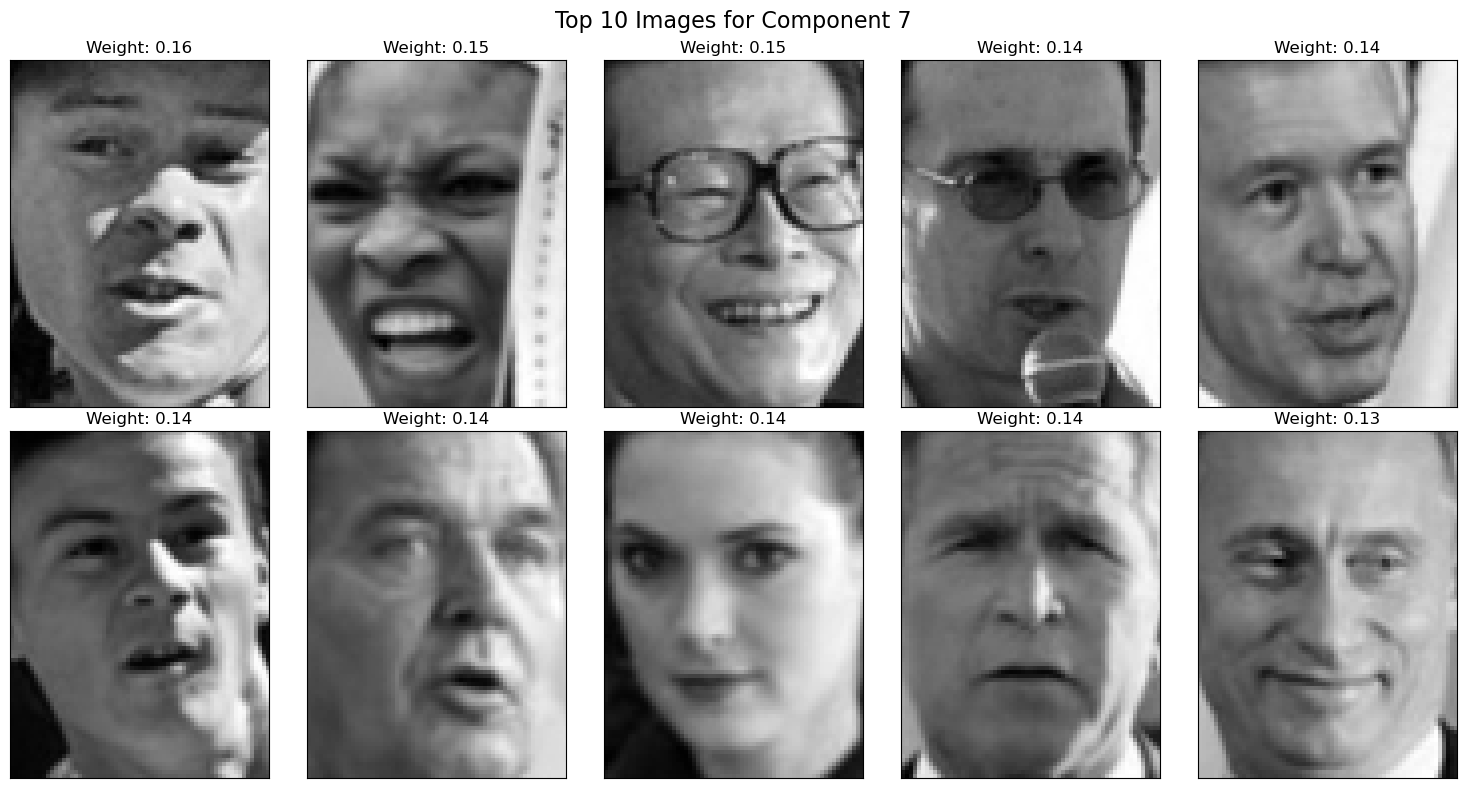

In [10]:
import matplotlib.pyplot as plt
import numpy as np


def plot_top_images(X_data, X_transformed, comp_idx, image_shape, n_top=10):
    """Plots the top images that strongly activate a given NMF component."""
    # Sort indices in descending order by component weight
    inds = np.argsort(X_transformed[:, comp_idx])[::-1][:n_top]

    fig, axes = plt.subplots(
        2, 5, figsize=(15, 8), subplot_kw={"xticks": (), "yticks": ()}
    )

    for ind, ax in zip(inds, axes.ravel()):
        # Show original image with a grayscale color map
        ax.imshow(X_data[ind].reshape(image_shape), cmap="gray")
        ax.set_title(f"Weight: {X_transformed[ind, comp_idx]:.2f}")

    fig.suptitle(
        f"Top {n_top} Images for Component {comp_idx}", fontsize=16
    )
    plt.tight_layout()
    plt.show()


# Plot top images for Component 3 and Component 7
plot_top_images(X_train, X_train_nmf, comp_idx=3, image_shape=image_shape)
plot_top_images(X_train, X_train_nmf, comp_idx=7, image_shape=image_shape)

Text(0, 0.5, 'Signal')

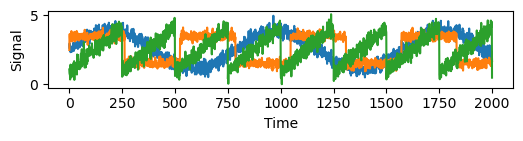

In [11]:
S = mglearn.datasets.make_signals()
plt.figure(figsize=(6, 1))
plt.plot(S,
'-')
plt.xlabel("Time")
plt.ylabel("Signal")

In [12]:
# mix data into a 100-dimensional state
A = np.random.RandomState(0).uniform(size=(100, 3))
X = np.dot(S, A.T)
print("Shape of measurements: {}".format(X.shape))

Shape of measurements: (2000, 100)


In [13]:
nmf = NMF(n_components=3, random_state=42)
S_ = nmf.fit_transform(X)
print("Recovered signal shape: {}".format(S_.shape))

Recovered signal shape: (2000, 3)


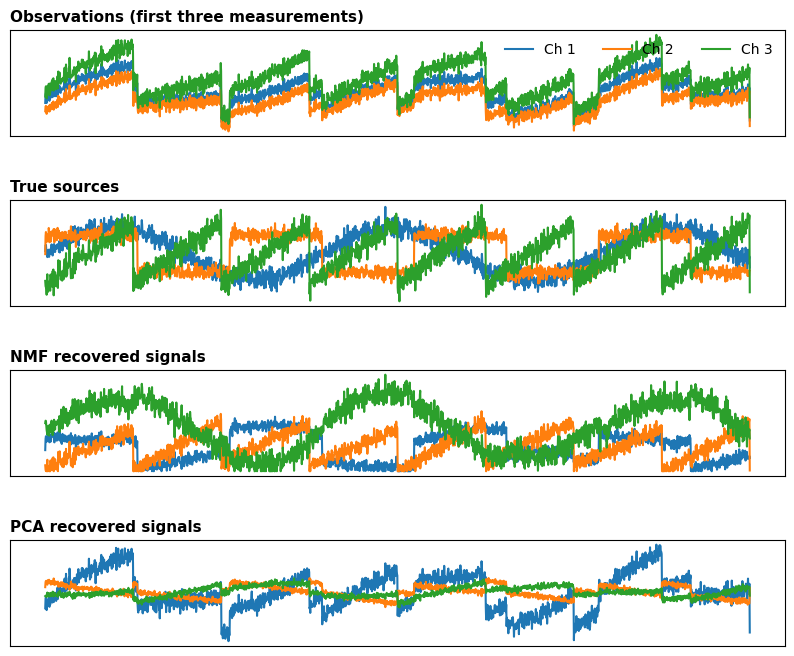

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# Perform PCA fit and transformation
pca = PCA(n_components=3)
H = pca.fit_transform(X)

# Organize model arrays and descriptions
models = [X, S, S_, H]
names = [
    "Observations (first three measurements)",
    "True sources",
    "NMF recovered signals",
    "PCA recovered signals",
]

# Create stacked subplots
fig, axes = plt.subplots(
    4, 1, figsize=(10, 8), gridspec_kw={"hspace": 0.6}, subplot_kw={"xticks": ()}
)

colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for model, name, ax in zip(models, names, axes):
    ax.set_title(name, fontsize=11, fontweight="bold", loc="left")
    # Plot up to first 3 components
    for col_idx in range(min(3, model.shape[1])):
        ax.plot(model[:, col_idx], label=f"Ch {col_idx+1}", color=colors[col_idx])
    ax.set_yticks([])

axes[0].legend(loc="upper right", ncol=3, frameon=False)
plt.show()

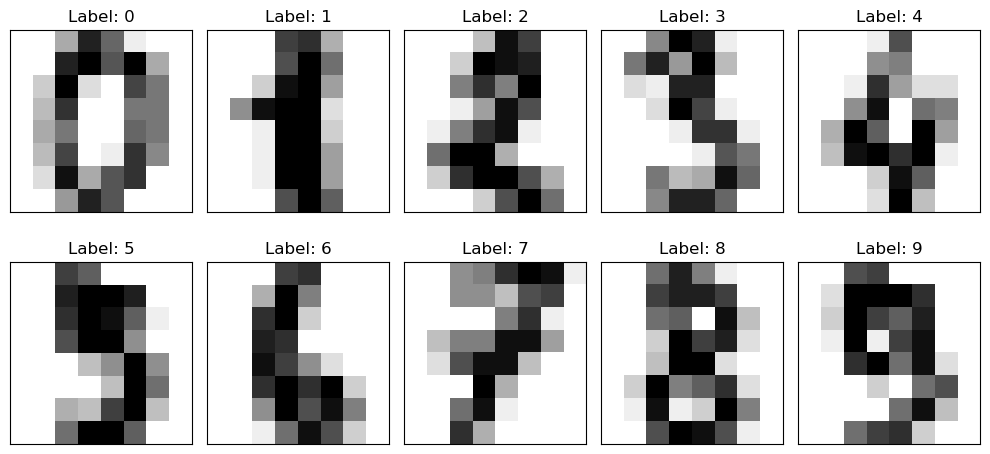

In [18]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# Load the digits dataset
digits = load_digits()

# Create subplots
fig, axes = plt.subplots(
    2, 5, figsize=(10, 5), subplot_kw={"xticks": (), "yticks": ()}
)

# Zip together subplots, images, and corresponding labels
for ax, img, target in zip(axes.ravel(), digits.images, digits.target):
    # Display in grayscale (inverted so dark numbers are on a white background)
    ax.imshow(img, cmap="binary")
    ax.set_title(f"Label: {target}")

plt.tight_layout()
plt.show()

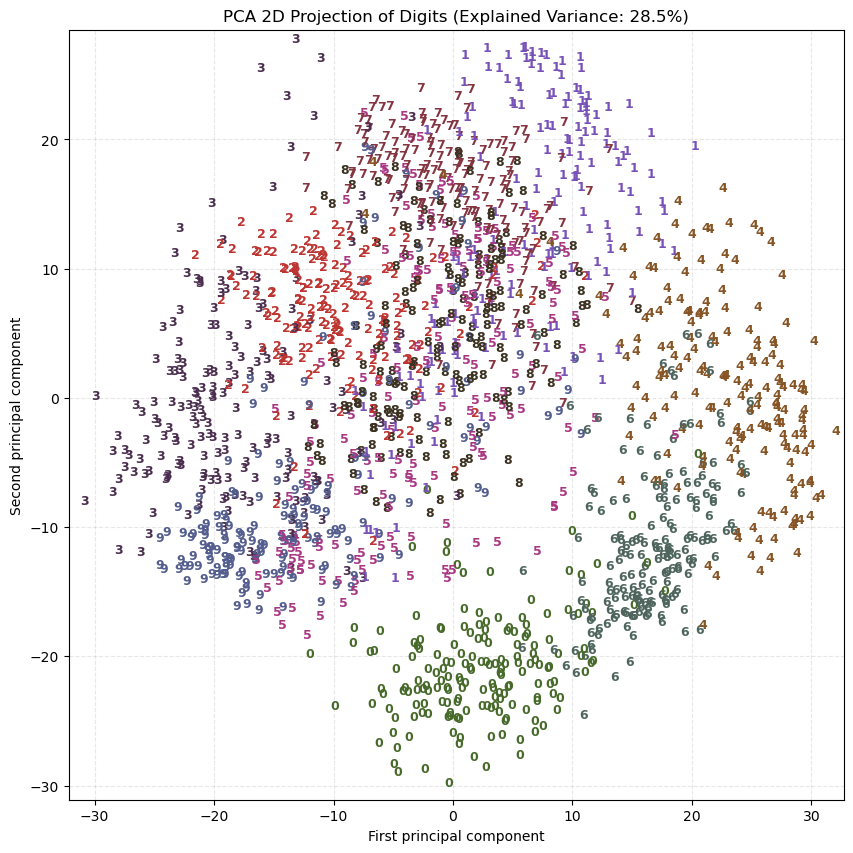

In [20]:
import matplotlib.pyplot as plt

# Fit PCA and transform to 2D space in one step
pca = PCA(n_components=2)
digits_pca = pca.fit_transform(digits.data)

# Color palette for classes 0 through 9
colors = [
    "#476A2A", "#7851B8", "#BD3430", "#4A2D4E", "#875525",
    "#A83683", "#4E655E", "#853541", "#3A3120", "#535D8E"
]

plt.figure(figsize=(10, 10))
plt.xlim(digits_pca[:, 0].min() - 1, digits_pca[:, 0].max() + 1)
plt.ylim(digits_pca[:, 1].min() - 1, digits_pca[:, 1].max() + 1)

# Overlay numeric labels at scatter points
for i in range(len(digits.data)):
    plt.text(
        digits_pca[i, 0],
        digits_pca[i, 1],
        str(digits.target[i]),
        color=colors[digits.target[i]],
        fontdict={"weight": "bold", "size": 9},
    )

var_exp = pca.explained_variance_ratio_.sum() * 100
plt.title(f"PCA 2D Projection of Digits (Explained Variance: {var_exp:.1f}%)")
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

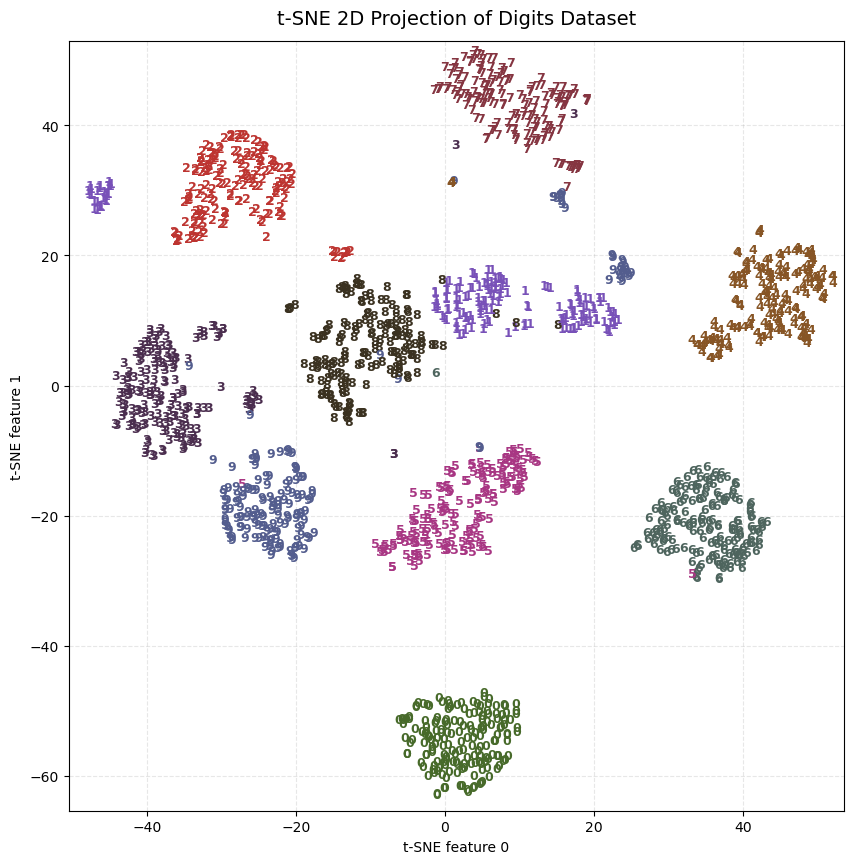

In [22]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Fit and transform in one step
tsne = TSNE(random_state=42)
digits_tsne = tsne.fit_transform(digits.data)

colors = [
    "#476A2A", "#7851B8", "#BD3430", "#4A2D4E", "#875525",
    "#A83683", "#4E655E", "#853541", "#3A3120", "#535D8E"
]

plt.figure(figsize=(10, 10))
plt.xlim(digits_tsne[:, 0].min() - 2, digits_tsne[:, 0].max() + 2)
plt.ylim(digits_tsne[:, 1].min() - 2, digits_tsne[:, 1].max() + 2)

# Overlay numeric labels at embedded positions
for i in range(len(digits.data)):
    plt.text(
        digits_tsne[i, 0],
        digits_tsne[i, 1],
        str(digits.target[i]),
        color=colors[digits.target[i]],
        fontdict={"weight": "bold", "size": 9},
    )

plt.title("t-SNE 2D Projection of Digits Dataset", fontsize=14, pad=12)
plt.xlabel("t-SNE feature 0")
plt.ylabel("t-SNE feature 1")  # Fixed duplicate xlabel bug
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

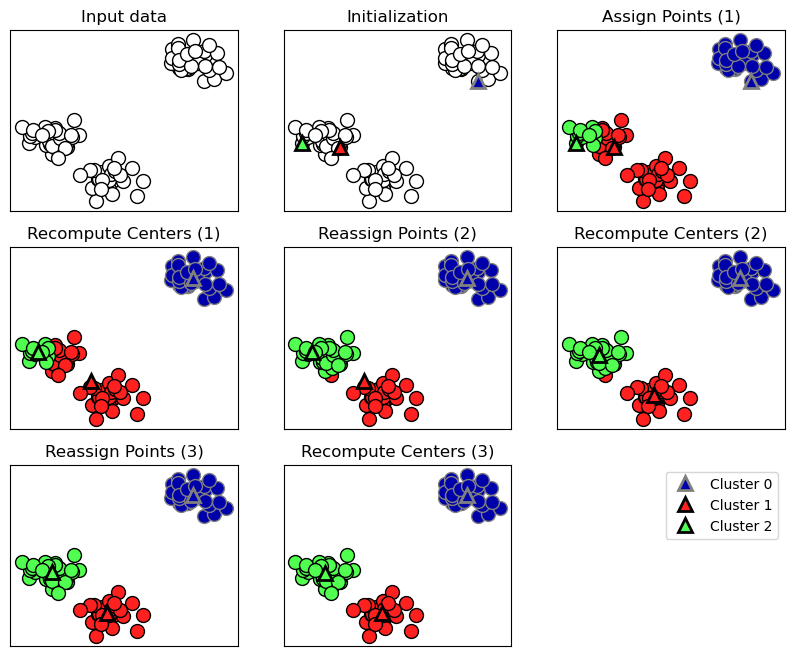

In [23]:
mglearn.plots.plot_kmeans_algorithm()

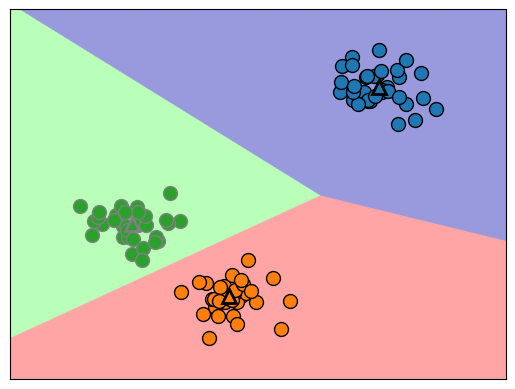

In [24]:
mglearn.plots.plot_kmeans_boundaries()

In [25]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
# generate synthetic two-dimensional data
X, y = make_blobs(random_state=1)
# build the clustering model
kmeans = KMeans(n_clusters=3)
kmeans.fit(X)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [26]:
print("Cluster memberships:\n{}".format(kmeans.labels_))

Cluster memberships:
[1 0 0 0 2 2 2 0 1 1 0 0 2 1 2 2 2 1 0 0 2 0 2 1 0 2 2 1 1 2 1 1 2 1 0 2 0
 0 0 2 2 0 1 0 0 2 1 1 1 1 0 2 2 2 1 2 0 0 1 1 0 2 2 0 0 2 1 2 1 0 0 0 2 1
 1 0 2 2 1 0 1 0 0 2 1 1 1 1 0 1 2 1 1 0 0 2 2 1 2 1]


In [27]:
print(kmeans.predict(X))

[1 0 0 0 2 2 2 0 1 1 0 0 2 1 2 2 2 1 0 0 2 0 2 1 0 2 2 1 1 2 1 1 2 1 0 2 0
 0 0 2 2 0 1 0 0 2 1 1 1 1 0 2 2 2 1 2 0 0 1 1 0 2 2 0 0 2 1 2 1 0 0 0 2 1
 1 0 2 2 1 0 1 0 0 2 1 1 1 1 0 1 2 1 1 0 0 2 2 1 2 1]


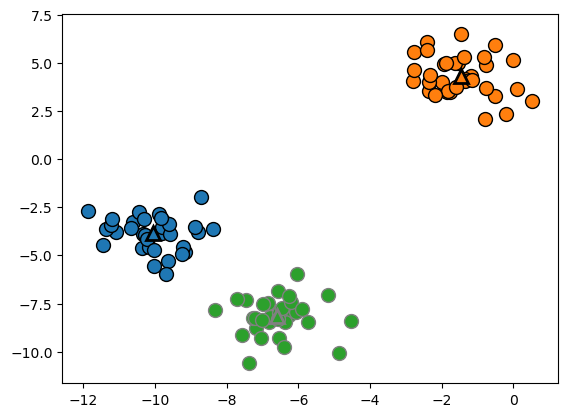

In [28]:
mglearn.discrete_scatter(X[:, 0], X[:, 1], kmeans.labels_, markers='o')
mglearn.discrete_scatter(
kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], [0, 1, 2],
markers='^'
, markeredgewidth=2)

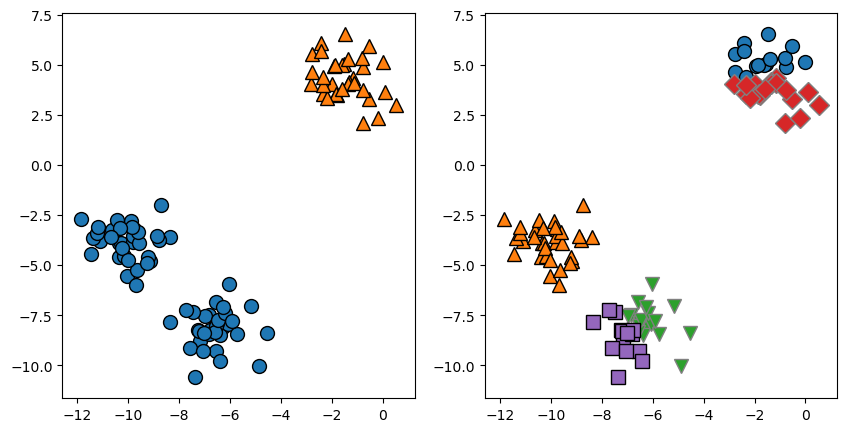

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
# using two cluster centers:
kmeans = KMeans(n_clusters=2)
kmeans.fit(X)
assignments = kmeans.labels_
mglearn.discrete_scatter(X[:, 0], X[:, 1], assignments, ax=axes[0])
# using five cluster centers:
kmeans = KMeans(n_clusters=5)
kmeans.fit(X)
assignments = kmeans.labels_
mglearn.discrete_scatter(X[:, 0], X[:, 1], assignments, ax=axes[1])

Text(0, 0.5, 'Feature 1')

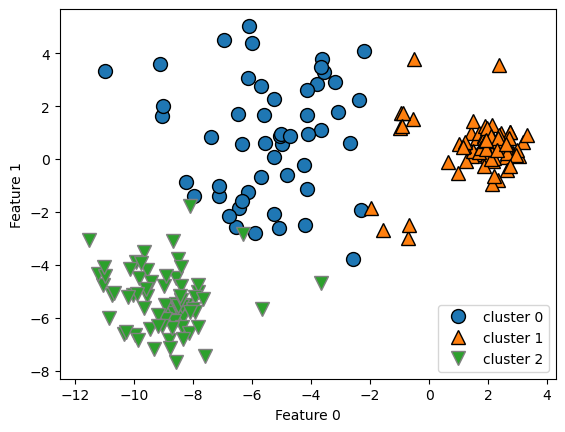

In [30]:
X_varied, y_varied = make_blobs(n_samples=200,
cluster_std=[1.0, 2.5, 0.5],
random_state=170)
y_pred = KMeans(n_clusters=3, random_state=0).fit_predict(X_varied)
mglearn.discrete_scatter(X_varied[:, 0], X_varied[:, 1], y_pred)
plt.legend(["cluster 0", "cluster 1", "cluster 2"], loc='best')
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

Text(0, 0.5, 'Feature 1')

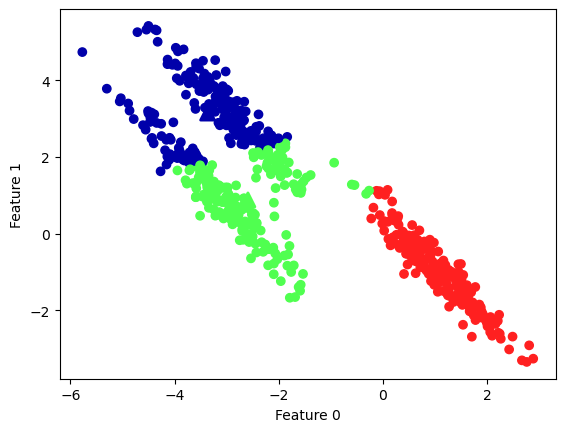

In [31]:
# generate some random cluster data
X, y = make_blobs(random_state=170, n_samples=600)
rng = np.random.RandomState(74)
# transform the data to be stretched
transformation = rng.normal(size=(2, 2))
X = np.dot(X, transformation)
# cluster the data into three clusters
kmeans = KMeans(n_clusters=3)
kmeans.fit(X)
y_pred = kmeans.predict(X)
# plot the cluster assignments and cluster centers
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap=mglearn.cm3)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
marker='^'
, c=[0, 1, 2], s=100, linewidth=2, cmap=mglearn.cm3)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

Text(0, 0.5, 'Feature 1')

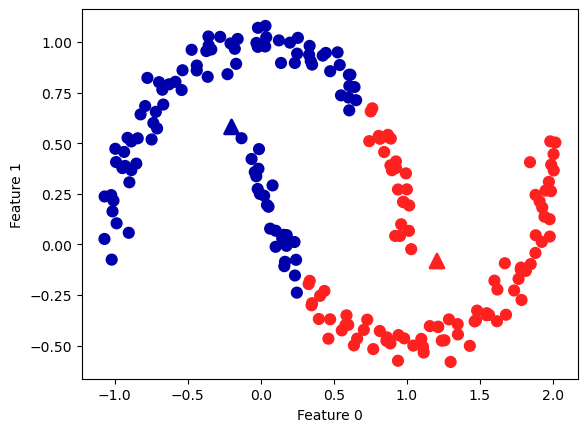

In [33]:
# generate synthetic two_moons data (with less noise this time)
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=200, noise=0.05, random_state=0)
# cluster the data into two clusters
kmeans = KMeans(n_clusters=2)
kmeans.fit(X)
y_pred = kmeans.predict(X)
# plot the cluster assignments and cluster centers
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap=mglearn.cm2, s=60)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
marker='^'
, c=[mglearn.cm2(0), mglearn.cm2(1)], s=100, linewidth=2)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

/opt/anaconda3/lib/python3.13/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(


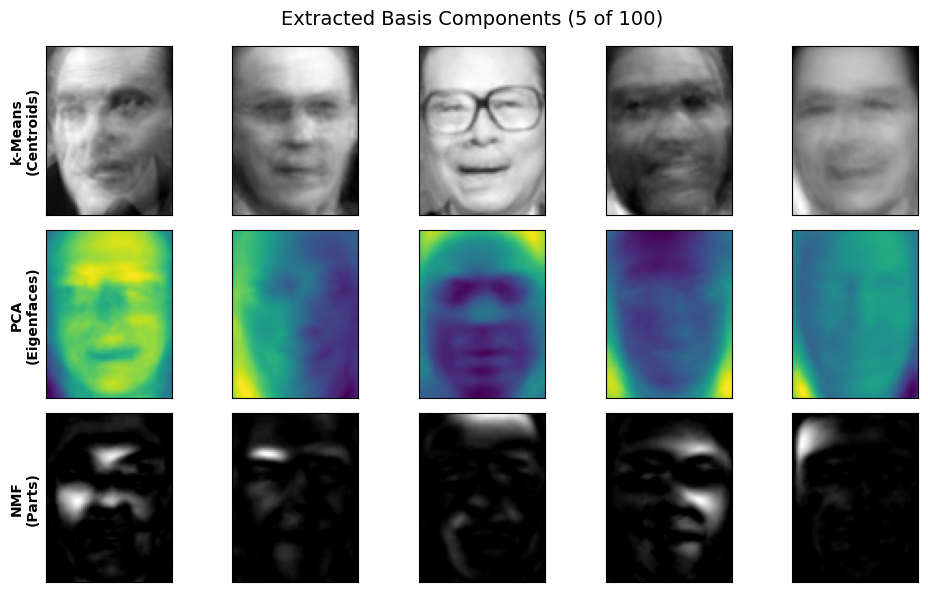

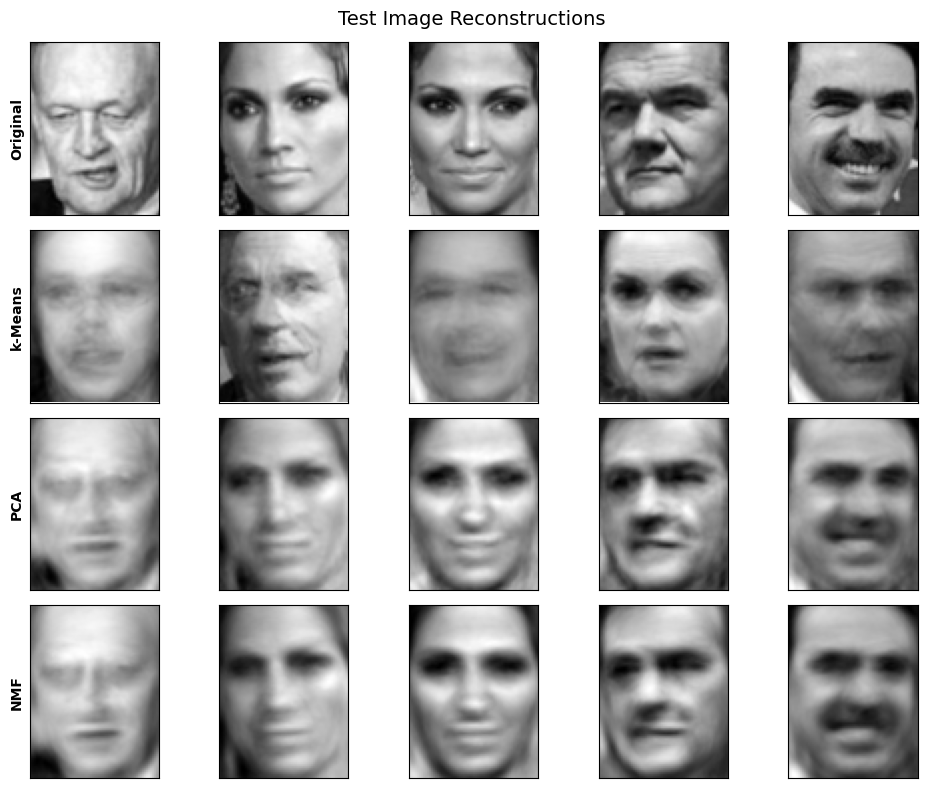

In [36]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF, PCA
from sklearn.model_selection import train_test_split

# 1. Train/Test Split & Fitting Models
X_train, X_test, y_train, y_test = train_test_split(
    X_people, y_people, stratify=y_people, random_state=0
)

nmf = NMF(n_components=100, random_state=0, max_iter=1000).fit(X_train)
pca = PCA(n_components=100, random_state=0).fit(X_train)
kmeans = KMeans(n_clusters=100, random_state=0, n_init=10).fit(X_train)

# 2. Compute Reconstructions for Test Images
X_reconstructed_pca = pca.inverse_transform(pca.transform(X_test))
X_reconstructed_kmeans = kmeans.cluster_centers_[kmeans.predict(X_test)]
X_reconstructed_nmf = np.dot(nmf.transform(X_test), nmf.components_)

# 3. Figure 1: Extracted Components / Basis Vectors
fig, axes = plt.subplots(
    3, 5, figsize=(10, 6), subplot_kw={"xticks": (), "yticks": ()}
)
fig.suptitle("Extracted Basis Components (5 of 100)", fontsize=14)

for ax, comp_kmeans, comp_pca, comp_nmf in zip(
    axes.T, kmeans.cluster_centers_, pca.components_, nmf.components_
):
    ax[0].imshow(comp_kmeans.reshape(image_shape), cmap="gray")
    ax[1].imshow(comp_pca.reshape(image_shape), cmap="viridis")
    ax[2].imshow(comp_nmf.reshape(image_shape), cmap="gray")

axes[0, 0].set_ylabel("k-Means\n(Centroids)", fontsize=10, fontweight="bold")
axes[1, 0].set_ylabel("PCA\n(Eigenfaces)", fontsize=10, fontweight="bold")
axes[2, 0].set_ylabel("NMF\n(Parts)", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

# 4. Figure 2: Image Reconstructions
fig, axes = plt.subplots(
    4, 5, figsize=(10, 8), subplot_kw={"xticks": (), "yticks": ()}
)
fig.suptitle("Test Image Reconstructions", fontsize=14)

for ax, orig, rec_kmeans, rec_pca, rec_nmf in zip(
    axes.T, X_test, X_reconstructed_kmeans, X_reconstructed_pca, X_reconstructed_nmf
):
    ax[0].imshow(orig.reshape(image_shape), cmap="gray")
    ax[1].imshow(rec_kmeans.reshape(image_shape), cmap="gray")
    ax[2].imshow(rec_pca.reshape(image_shape), cmap="gray")
    ax[3].imshow(rec_nmf.reshape(image_shape), cmap="gray")

axes[0, 0].set_ylabel("Original", fontsize=10, fontweight="bold")
axes[1, 0].set_ylabel("k-Means", fontsize=10, fontweight="bold")
axes[2, 0].set_ylabel("PCA", fontsize=10, fontweight="bold")
axes[3, 0].set_ylabel("NMF", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

Cluster memberships:
[8 4 6 3 1 1 5 2 8 4 9 2 1 4 7 5 0 2 0 7 1 2 0 4 9 6 1 1 6 0 8 9 2 6 8 1 2
 5 3 6 2 7 8 6 4 9 5 7 6 2 7 2 1 3 4 8 0 4 0 9 2 3 1 8 4 3 9 4 9 3 2 3 2 6
 2 3 6 8 0 2 1 9 2 1 6 9 5 9 2 1 0 5 1 7 1 1 4 2 3 6 4 1 9 5 3 6 3 7 4 0 7
 9 9 3 8 4 8 1 2 8 8 7 6 9 6 7 5 6 4 1 5 7 3 6 4 4 4 3 1 8 6 6 0 9 7 5 6 4
 0 6 2 4 8 0 2 9 4 2 0 0 6 4 0 4 2 1 0 2 4 2 0 3 3 7 6 2 1 7 7 0 4 3 1 4 1
 0 9 2 3 7 3 0 8 5 6 7 1 6 9 4]


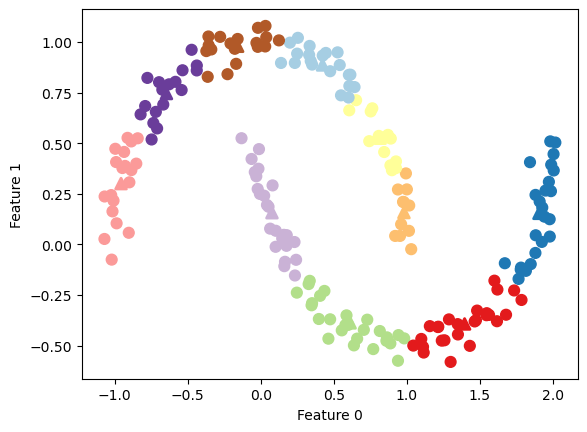

In [37]:
X, y = make_moons(n_samples=200, noise=0.05, random_state=0)
kmeans = KMeans(n_clusters=10, random_state=0)
kmeans.fit(X)
y_pred = kmeans.predict(X)
plt.scatter(X[:, 0], X[:, 1], c=y_pred, s=60, cmap='Paired')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=60,
marker='^'
, c=range(kmeans.n_clusters), linewidth=2, cmap='Paired')
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
print("Cluster memberships:\n{}".format(y_pred))

In [38]:
distance_features = kmeans.transform(X)
print("Distance feature shape: {}".format(distance_features.shape))
print("Distance features:\n{}".format(distance_features))

Distance feature shape: (200, 10)
Distance features:
[[0.53664613 1.15017588 0.93237626 ... 1.48034956 0.002907   1.07736639]
 [1.74138152 0.60592307 1.00666225 ... 2.52921971 1.20779969 2.23716489]
 [0.75710543 1.93145038 0.91586549 ... 0.78321505 0.87573753 0.71838465]
 ...
 [0.9274342  1.73811046 0.57899268 ... 1.11471941 0.83358544 1.04125672]
 [0.3227627  1.97647071 1.47861069 ... 0.81425026 0.84551232 0.28446737]
 [1.63322944 0.47226506 1.02289983 ... 2.46626118 1.09767675 2.14812753]]


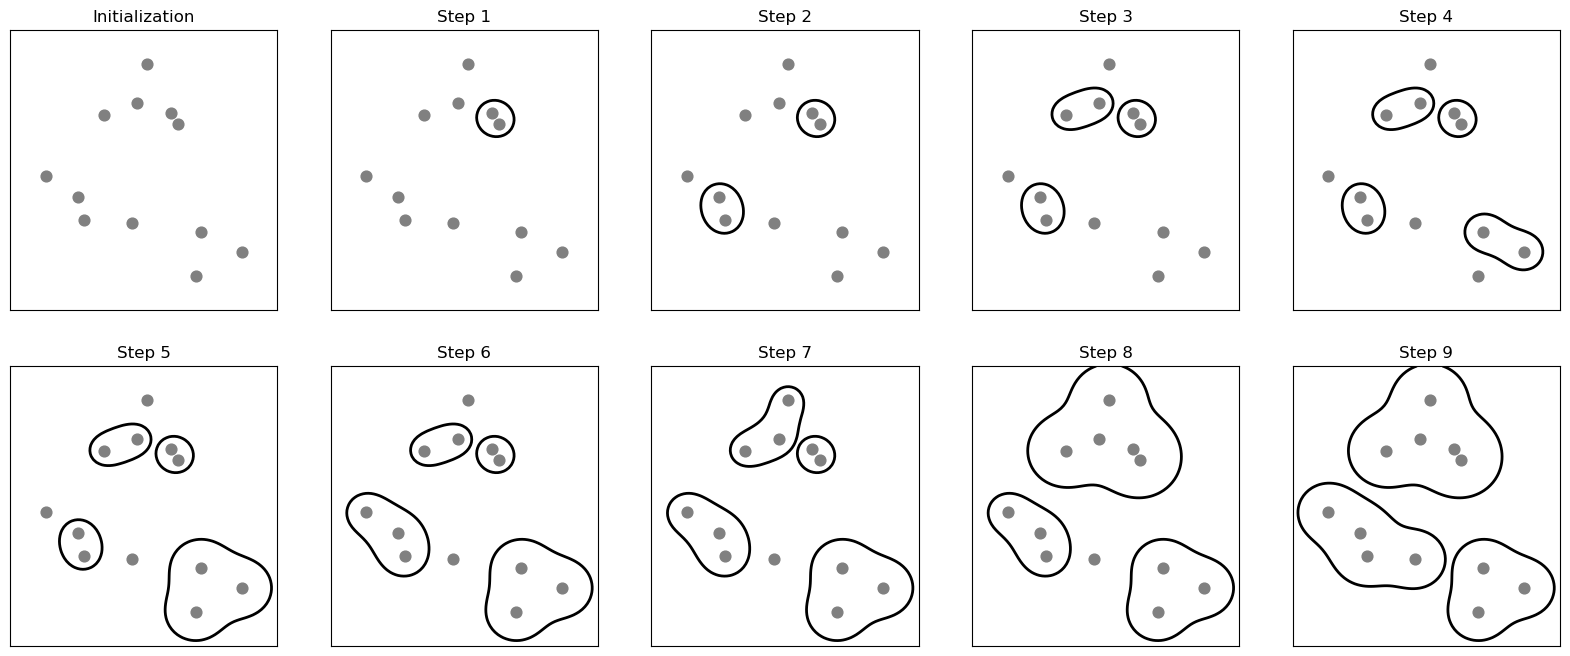

In [39]:
mglearn.plots.plot_agglomerative_algorithm()

Text(0, 0.5, 'Feature 1')

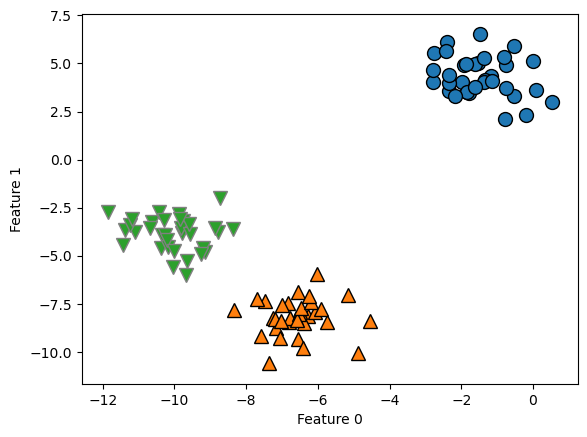

In [40]:
from sklearn.cluster import AgglomerativeClustering
X, y = make_blobs(random_state=1)
agg = AgglomerativeClustering(n_clusters=3)
assignment = agg.fit_predict(X)
mglearn.discrete_scatter(X[:, 0], X[:, 1], assignment)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

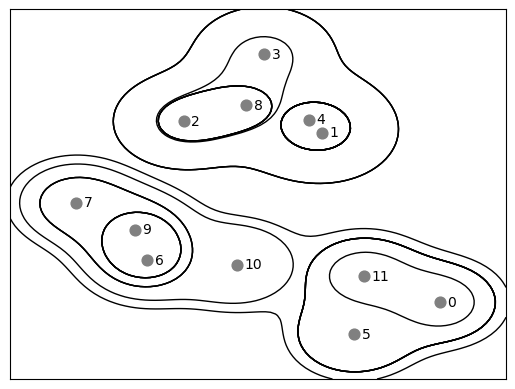

In [41]:
mglearn.plots.plot_agglomerative()

Text(0, 0.5, 'Cluster distance')

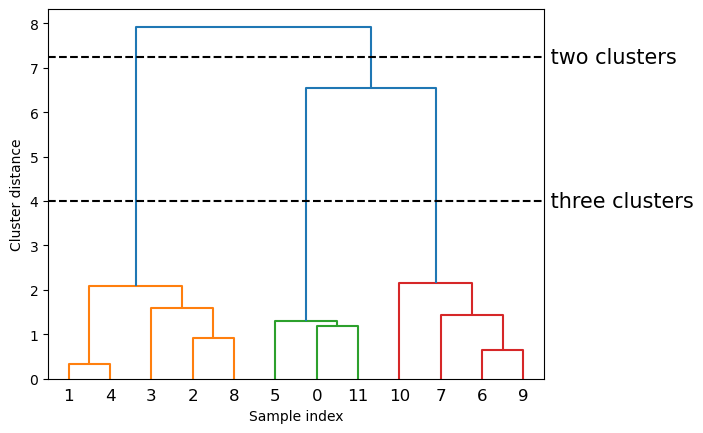

In [43]:
# Import the dendrogram function and the ward clustering function from SciPy
from scipy.cluster.hierarchy import dendrogram, ward
X, y = make_blobs(random_state=0, n_samples=12)
# Apply the ward clustering to the data array X
# The SciPy ward function returns an array that specifies the distances
# bridged when performing agglomerative clustering
linkage_array = ward(X)
# Now we plot the dendrogram for the linkage_array containing the distances
# between clusters
dendrogram(linkage_array)
# Mark the cuts in the tree that signify two or three clusters
ax = plt.gca()
bounds = ax.get_xbound()
ax.plot(bounds, [7.25, 7.25], '--'
, c='k')
ax.plot(bounds, [4, 4], '--'
, c='k')
ax.text(bounds[1], 7.25, ' two clusters', va='center', fontdict={'size': 15})
ax.text(bounds[1], 4, ' three clusters', va='center', fontdict={'size': 15})
plt.xlabel("Sample index")
plt.ylabel("Cluster distance")

In [44]:
from sklearn.cluster import DBSCAN
X, y = make_blobs(random_state=0, n_samples=12)
dbscan = DBSCAN()
clusters = dbscan.fit_predict(X)
print("Cluster memberships:\n{}".format(clusters))

Cluster memberships:
[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]


min_samples: 2 eps: 1.000000  cluster: [-1  0  0 -1  0 -1  1  1  0  1 -1 -1]
min_samples: 2 eps: 1.500000  cluster: [0 1 1 1 1 0 2 2 1 2 2 0]
min_samples: 2 eps: 2.000000  cluster: [0 1 1 1 1 0 0 0 1 0 0 0]
min_samples: 2 eps: 3.000000  cluster: [0 0 0 0 0 0 0 0 0 0 0 0]
min_samples: 3 eps: 1.000000  cluster: [-1  0  0 -1  0 -1  1  1  0  1 -1 -1]
min_samples: 3 eps: 1.500000  cluster: [0 1 1 1 1 0 2 2 1 2 2 0]
min_samples: 3 eps: 2.000000  cluster: [0 1 1 1 1 0 0 0 1 0 0 0]
min_samples: 3 eps: 3.000000  cluster: [0 0 0 0 0 0 0 0 0 0 0 0]
min_samples: 5 eps: 1.000000  cluster: [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
min_samples: 5 eps: 1.500000  cluster: [-1  0  0  0  0 -1 -1 -1  0 -1 -1 -1]
min_samples: 5 eps: 2.000000  cluster: [-1  0  0  0  0 -1 -1 -1  0 -1 -1 -1]
min_samples: 5 eps: 3.000000  cluster: [0 0 0 0 0 0 0 0 0 0 0 0]


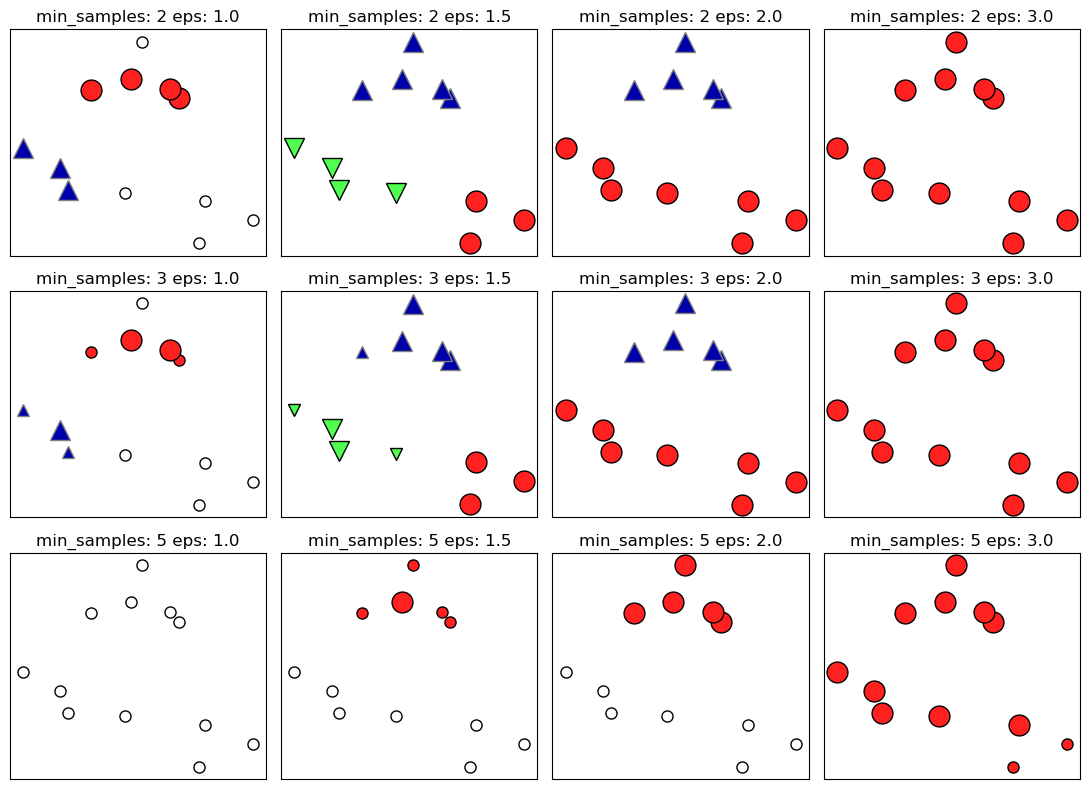

In [45]:
mglearn.plots.plot_dbscan()

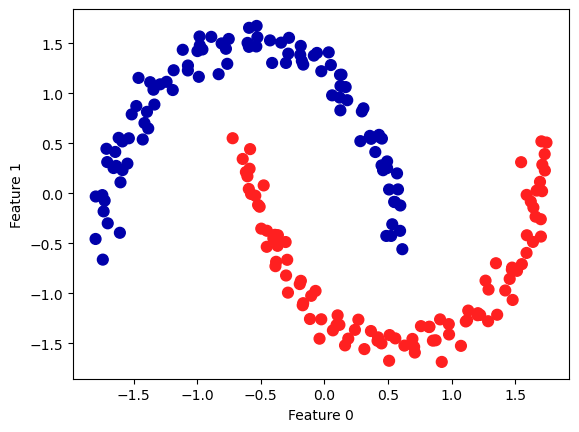

In [47]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import mglearn

# Create the moon-shaped dataset
X, y = make_moons(
    n_samples=200,
    noise=0.05,
    random_state=0
)

# Rescale the data to zero mean and unit variance
scaler = StandardScaler()
scaler.fit(X)

X_scaled = scaler.transform(X)

# Apply DBSCAN
dbscan = DBSCAN()
clusters = dbscan.fit_predict(X_scaled)

# Plot the cluster assignments
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap=mglearn.cm2,
    s=60
)

plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.show()

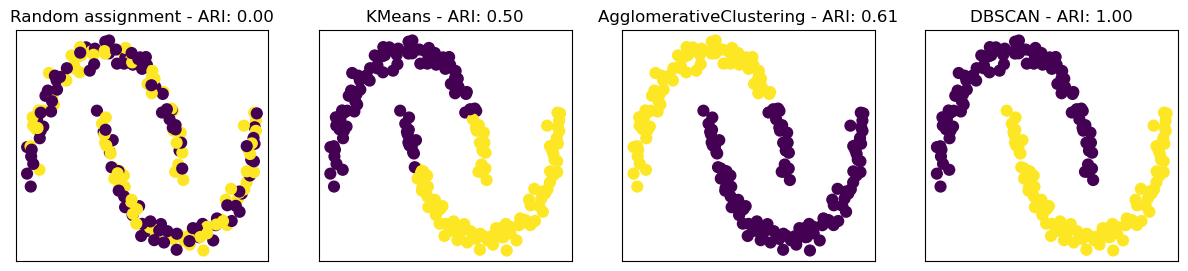

In [49]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics.cluster import adjusted_rand_score

# Create the moon-shaped dataset
X, y = make_moons(
    n_samples=200,
    noise=0.05,
    random_state=0
)

# Rescale the data to zero mean and unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a 1 x 4 figure
fig, axes = plt.subplots(
    1, 4,
    figsize=(15, 3),
    subplot_kw={'xticks': (), 'yticks': ()}
)

# List of clustering algorithms
algorithms = [
    KMeans(n_clusters=2, random_state=0),
    AgglomerativeClustering(n_clusters=2),
    DBSCAN()
]

# Create random cluster assignments for reference
random_state = np.random.RandomState(seed=0)

random_clusters = random_state.randint(
    low=0,
    high=2,
    size=len(X)
)

# Plot random assignment
axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=random_clusters,
    cmap='viridis',
    s=60
)

axes[0].set_title(
    "Random assignment - ARI: {:.2f}".format(
        adjusted_rand_score(y, random_clusters)
    )
)

# Plot each clustering algorithm
for ax, algorithm in zip(axes[1:], algorithms):

    clusters = algorithm.fit_predict(X_scaled)

    ax.scatter(
        X_scaled[:, 0],
        X_scaled[:, 1],
        c=clusters,
        cmap='viridis',
        s=60
    )

    ax.set_title(
        "{} - ARI: {:.2f}".format(
            algorithm.__class__.__name__,
            adjusted_rand_score(y, clusters)
        )
    )

plt.show()

In [50]:
from sklearn.metrics import accuracy_score
# these two labelings of points correspond to the same clustering
clusters1 = [0, 0, 1, 1, 0]
clusters2 = [1, 1, 0, 0, 1]
# accuracy is zero, as none of the labels are the same
print("Accuracy: {:.2f}".format(accuracy_score(clusters1, clusters2)))
# adjusted rand score is 1, as the clustering is exactly the same
print("ARI: {:.2f}".format(adjusted_rand_score(clusters1, clusters2)))

Accuracy: 0.00
ARI: 1.00


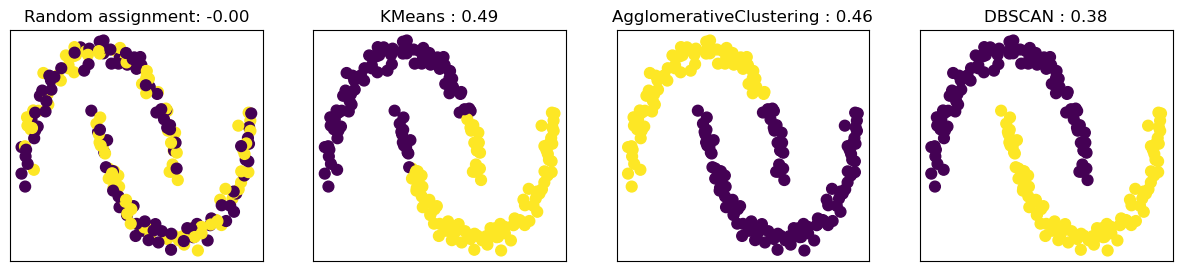

In [53]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

# Create the moon-shaped dataset
X, y = make_moons(
    n_samples=200,
    noise=0.05,
    random_state=0
)

# Rescale the data to zero mean and unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create 1 x 4 plots
fig, axes = plt.subplots(
    1, 4,
    figsize=(15, 3),
    subplot_kw={'xticks': (), 'yticks': ()}
)

# Create random cluster assignment
random_state = np.random.RandomState(seed=0)

random_clusters = random_state.randint(
    low=0,
    high=2,
    size=len(X)
)

# Plot random assignment
axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=random_clusters,
    cmap='viridis',
    s=60
)

axes[0].set_title(
    "Random assignment: {:.2f}".format(
        silhouette_score(X_scaled, random_clusters)
    )
)

# List of clustering algorithms
algorithms = [
    KMeans(n_clusters=2, random_state=0),
    AgglomerativeClustering(n_clusters=2),
    DBSCAN()
]

# Apply each algorithm
for ax, algorithm in zip(axes[1:], algorithms):

    clusters = algorithm.fit_predict(X_scaled)

    # Plot cluster assignments
    ax.scatter(
        X_scaled[:, 0],
        X_scaled[:, 1],
        c=clusters,
        cmap='viridis',
        s=60
    )

    # Calculate silhouette score
    score = silhouette_score(X_scaled, clusters)

    ax.set_title(
        "{} : {:.2f}".format(
            algorithm.__class__.__name__,
            score
        )
    )

plt.show()

In [55]:
# extract eigenfaces from lfw data and transform data
from sklearn.decomposition import PCA
pca = PCA(n_components=100, whiten=True, random_state=0)
pca.fit_transform(X_people)
X_pca = pca.transform(X_people)
# apply DBSCAN with default parameters
dbscan = DBSCAN()
labels = dbscan.fit_predict(X_pca)
print("Unique labels: {}".format(np.unique(labels)))

Unique labels: [-1]


In [56]:
dbscan = DBSCAN(min_samples=3)
labels = dbscan.fit_predict(X_pca)
print("Unique labels: {}".format(np.unique(labels)))

Unique labels: [-1]


In [57]:
dbscan = DBSCAN(min_samples=3, eps=15)
labels = dbscan.fit_predict(X_pca)
print("Unique labels: {}".format(np.unique(labels)))

Unique labels: [-1  0]


In [58]:
# Count number of points in all clusters and noise.
# bincount doesn't allow negative numbers, so we need to add 1.
# The first number in the result corresponds to noise points.
print("Number of points per cluster: {}".format(np.bincount(labels + 1)))

Number of points per cluster: [  37 2026]


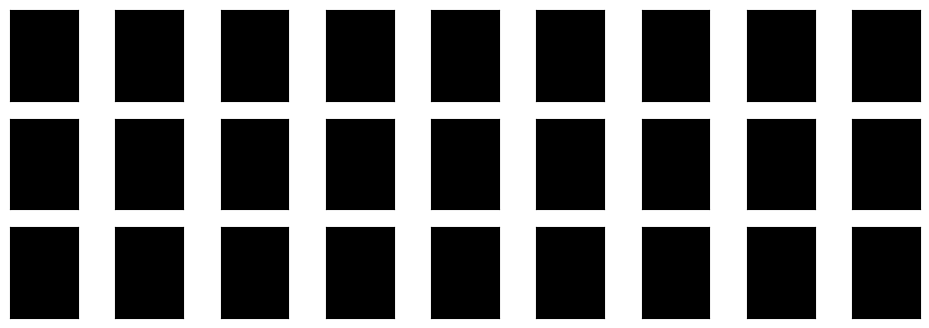

In [60]:
# Select images classified as noise
noise = X_people[labels == -1]

# Create a 3 x 9 grid
fig, axes = plt.subplots(
    3, 9,
    subplot_kw={'xticks': (), 'yticks': ()},
    figsize=(12, 4)
)

# Display the noise images
for image, ax in zip(noise, axes.ravel()):
    ax.imshow(
        image.reshape(image_shape),
        vmin=0,
        vmax=1,
        cmap='gray'
    )

plt.show()

In [62]:
import numpy as np
from sklearn.cluster import DBSCAN

for eps in [1, 3, 5, 7, 9, 11, 13]:

    print("\neps={}".format(eps))

    dbscan = DBSCAN(
        eps=eps,
        min_samples=3
    )

    labels = dbscan.fit_predict(X_pca)

    print("Clusters present: {}".format(np.unique(labels)))

    print("Cluster sizes: {}".format(
        np.bincount(labels + 1)
    ))


eps=1
Clusters present: [-1]
Cluster sizes: [2063]

eps=3
Clusters present: [-1]
Cluster sizes: [2063]

eps=5
Clusters present: [-1  0]
Cluster sizes: [2059    4]

eps=7
Clusters present: [-1  0  1  2  3  4  5]
Cluster sizes: [1957   75    4   14    6    4    3]

eps=9
Clusters present: [-1  0  1]
Cluster sizes: [1196  864    3]

eps=11
Clusters present: [-1  0]
Cluster sizes: [ 404 1659]

eps=13
Clusters present: [-1  0]
Cluster sizes: [ 119 1944]


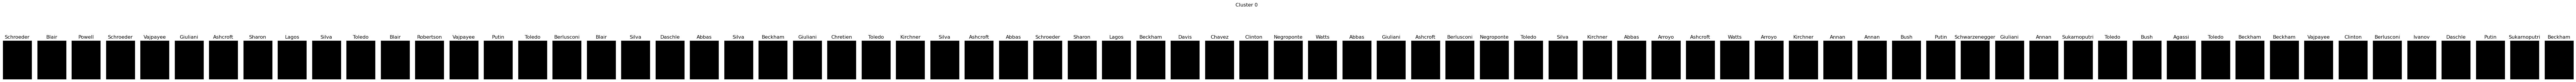

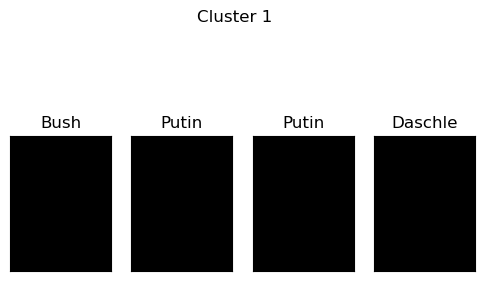

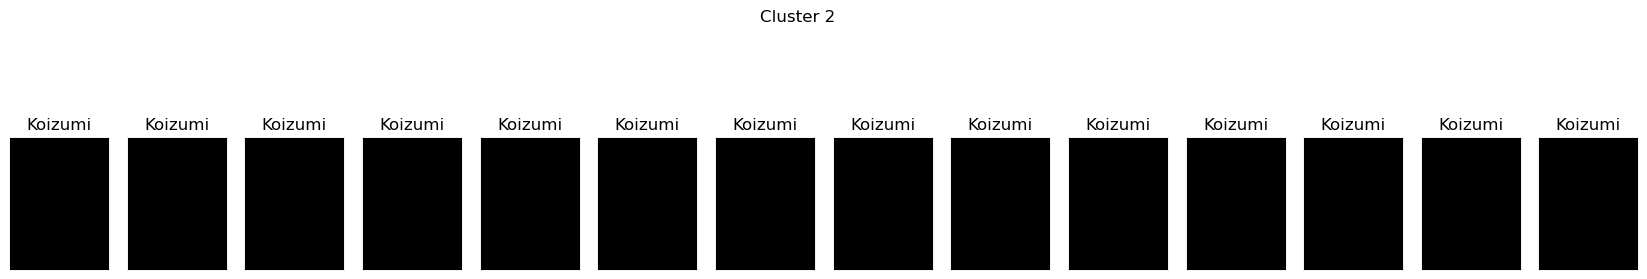

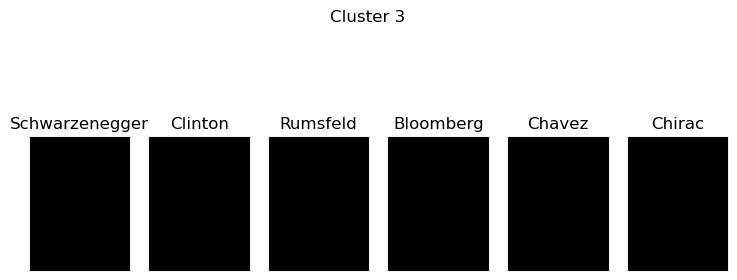

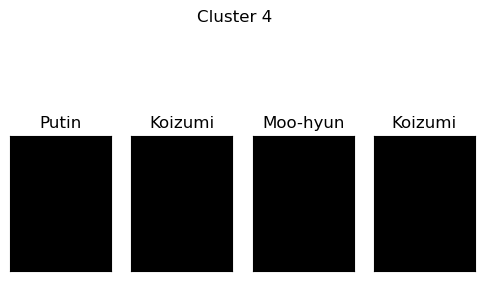

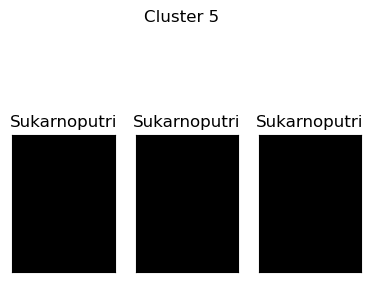

In [64]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

# Apply DBSCAN
dbscan = DBSCAN(min_samples=3, eps=7)
labels = dbscan.fit_predict(X_pca)

# Plot each cluster
for cluster in range(max(labels) + 1):

    mask = labels == cluster
    n_images = np.sum(mask)

    fig, axes = plt.subplots(
        1,
        n_images,
        figsize=(n_images * 1.5, 4),
        subplot_kw={'xticks': (), 'yticks': ()}
    )

    # Make axes iterable even when there is only one image
    axes = np.atleast_1d(axes)

    for image, label, ax in zip(
        X_people[mask],
        y_people[mask],
        axes
    ):
        ax.imshow(
            image.reshape(image_shape),
            vmin=0,
            vmax=1,
            cmap='gray'
        )

        ax.set_title(
            people.target_names[label].split()[-1]
        )

    plt.suptitle("Cluster {}".format(cluster))
    plt.show()

In [65]:
# extract clusters with k-means
km = KMeans(n_clusters=10, random_state=0)
labels_km = km.fit_predict(X_pca)
print("Cluster sizes k-means: {}".format(np.bincount(labels_km)))

Cluster sizes k-means: [  7 344 180 279 134 470   1 307   2 339]


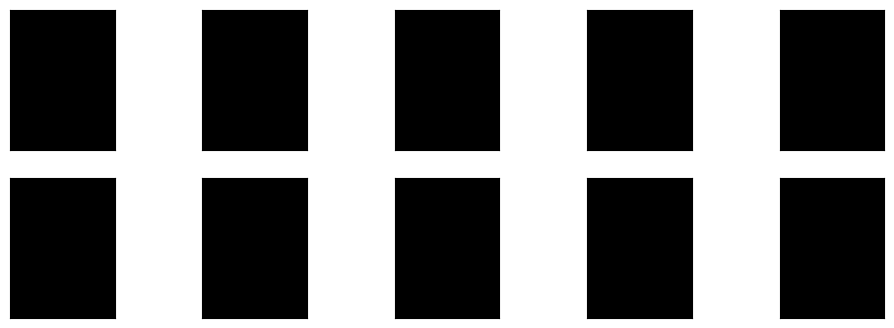

In [67]:
fig, axes = plt.subplots(
    2, 5,
    subplot_kw={'xticks': (), 'yticks': ()},
    figsize=(12, 4)
)

for center, ax in zip(km.cluster_centers_, axes.ravel()):
    ax.imshow(
        pca.inverse_transform(center).reshape(image_shape),
        vmin=0,
        vmax=1,
        cmap='gray'
    )

plt.show()

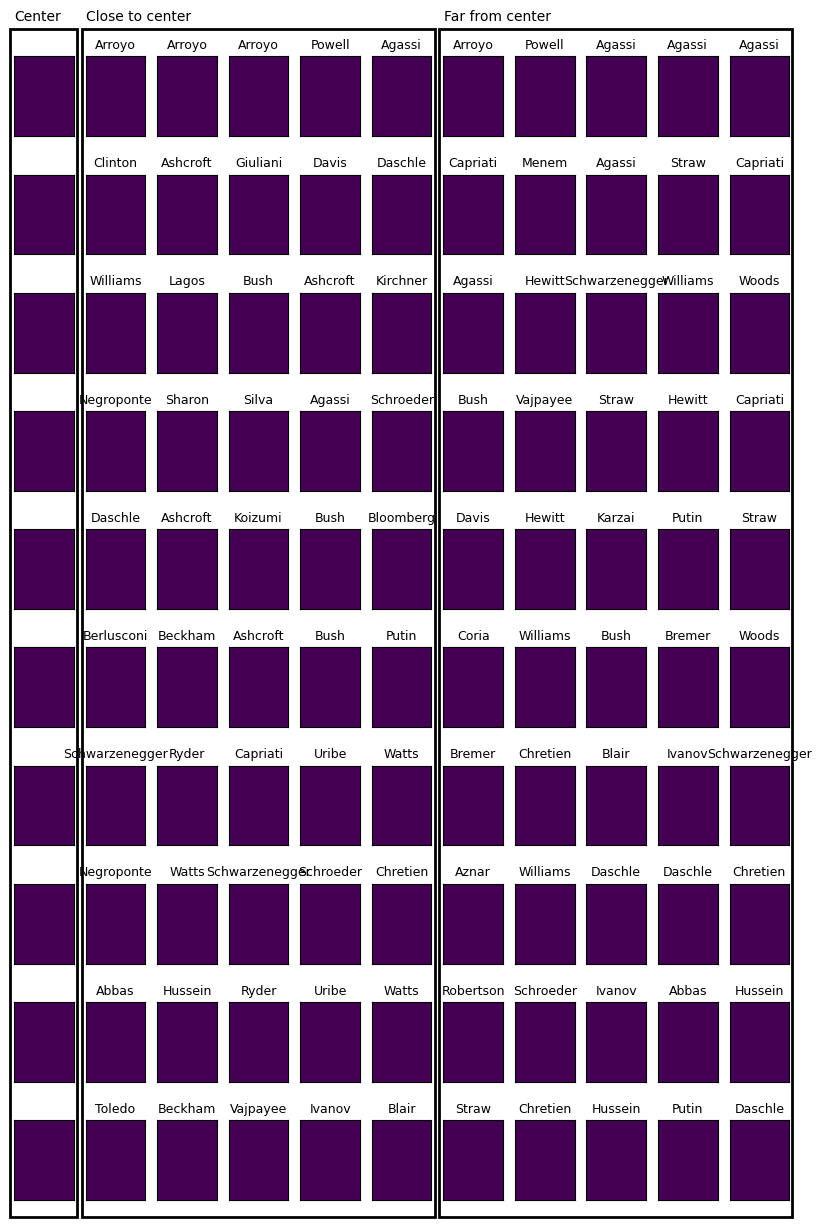

In [68]:
mglearn.plots.plot_kmeans_faces(km, pca, X_pca, X_people,
y_people, people.target_names)

In [69]:
# extract clusters with ward agglomerative clustering
agglomerative = AgglomerativeClustering(n_clusters=10)
labels_agg = agglomerative.fit_predict(X_pca)
print("Cluster sizes agglomerative clustering: {}".format(
np.bincount(labels_agg)))

Cluster sizes agglomerative clustering: [ 56 101  94 140 154 596 269 178  61 414]


In [70]:
print("ARI: {:.2f}".format(adjusted_rand_score(labels_agg, labels_km)))

ARI: 0.07


Text(0, 0.5, 'Cluster distance')

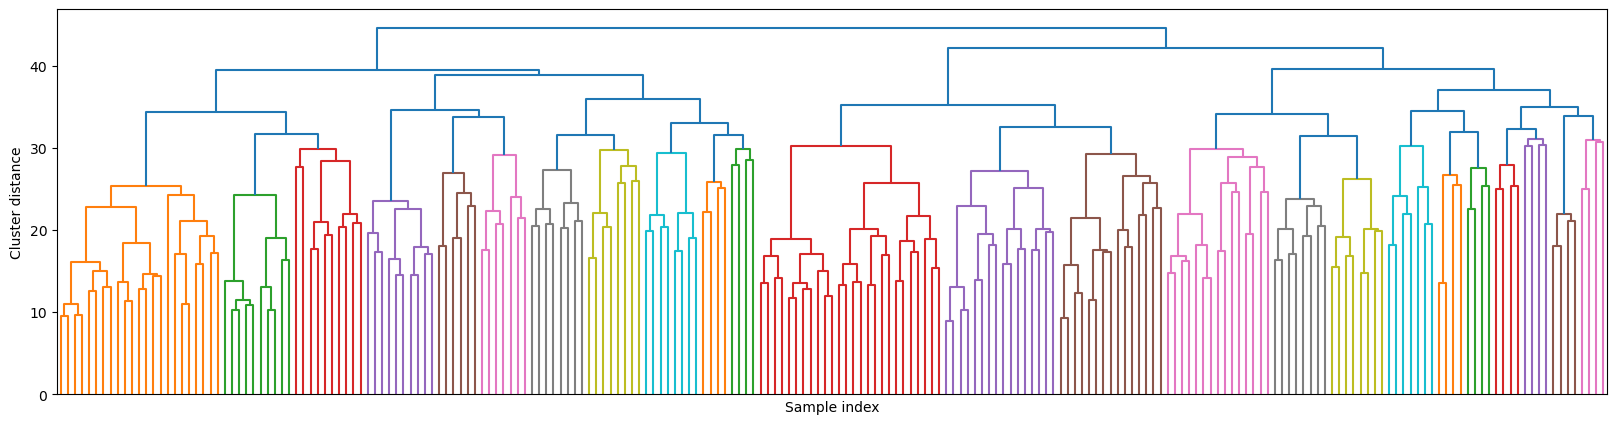

In [71]:
linkage_array = ward(X_pca)
# now we plot the dendrogram for the linkage_array
# containing the distances between clusters
plt.figure(figsize=(20, 5))
dendrogram(linkage_array, p=7, truncate_mode='level', no_labels=True)
plt.xlabel("Sample index")
plt.ylabel("Cluster distance")

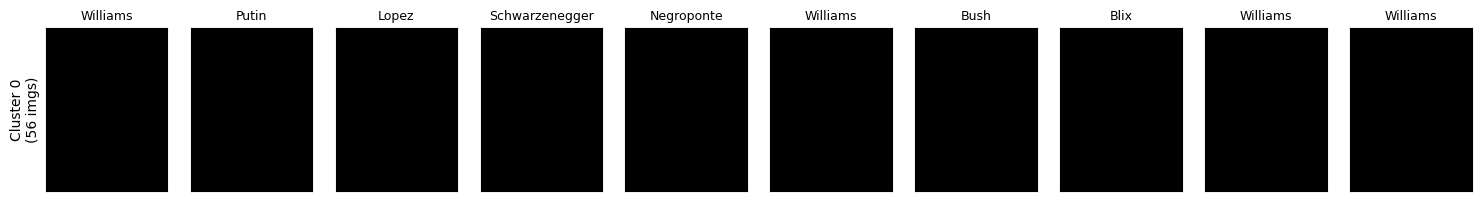

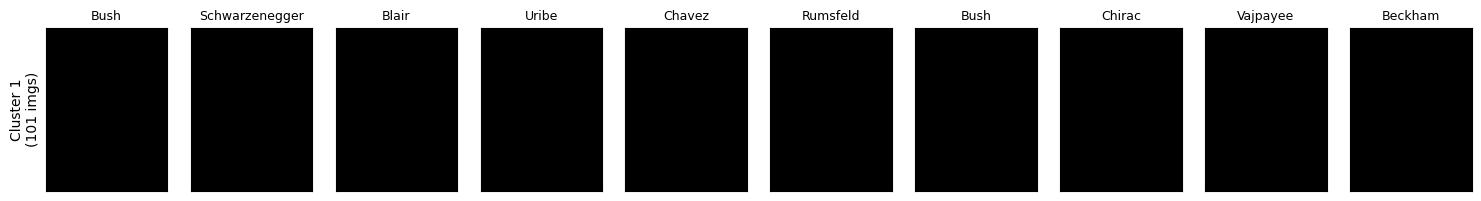

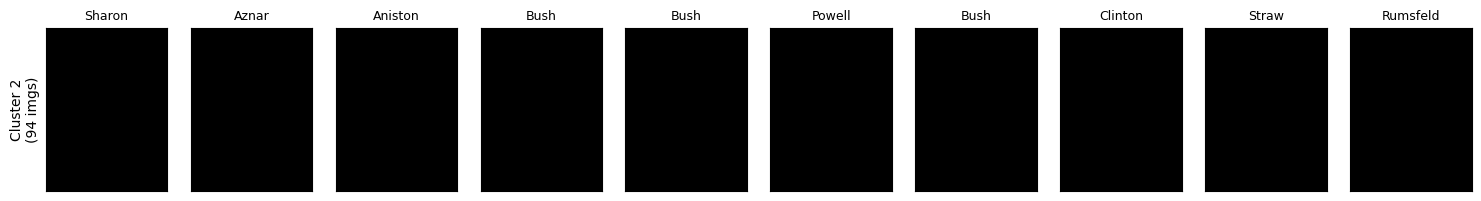

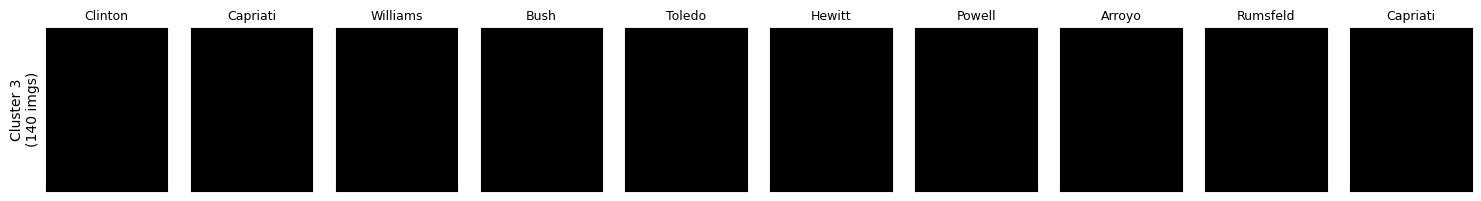

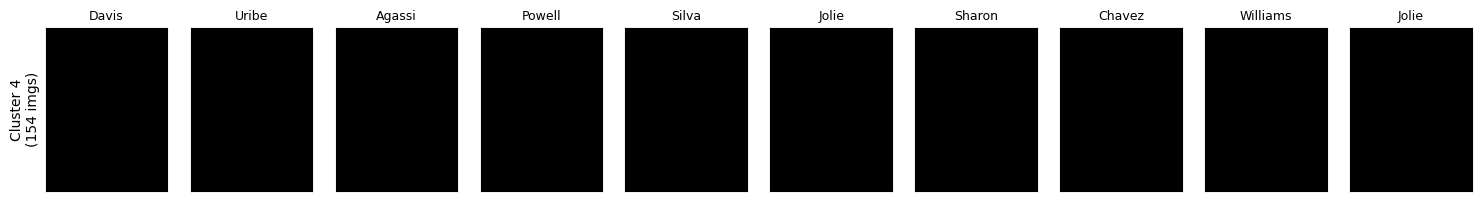

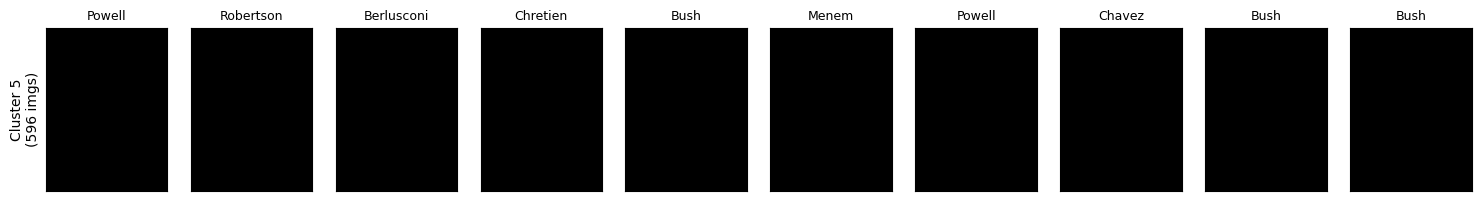

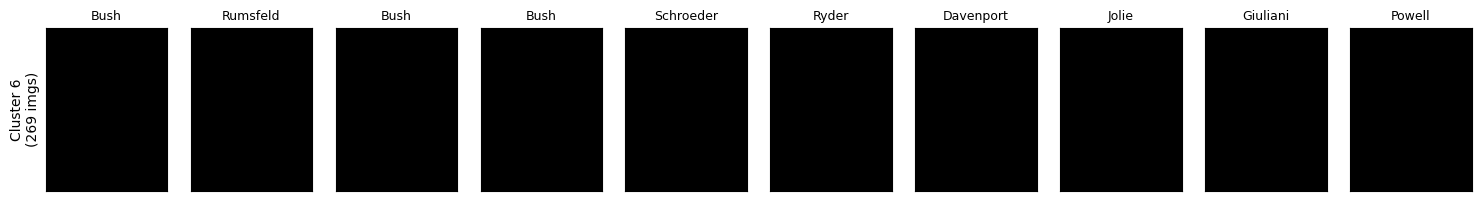

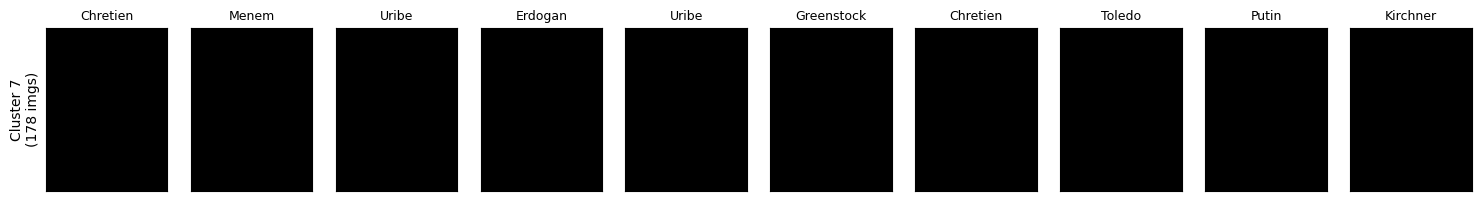

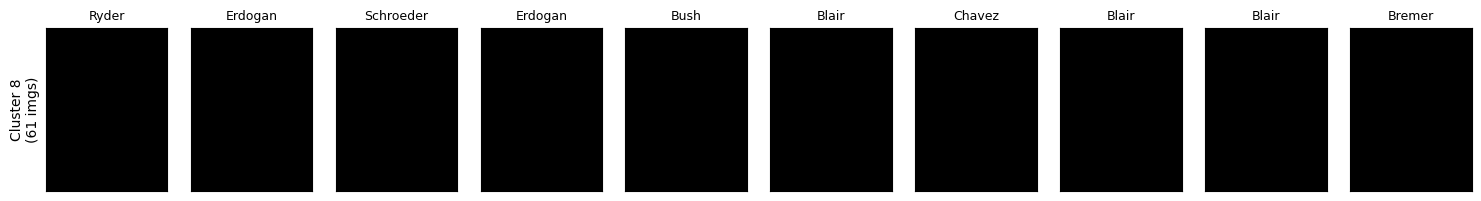

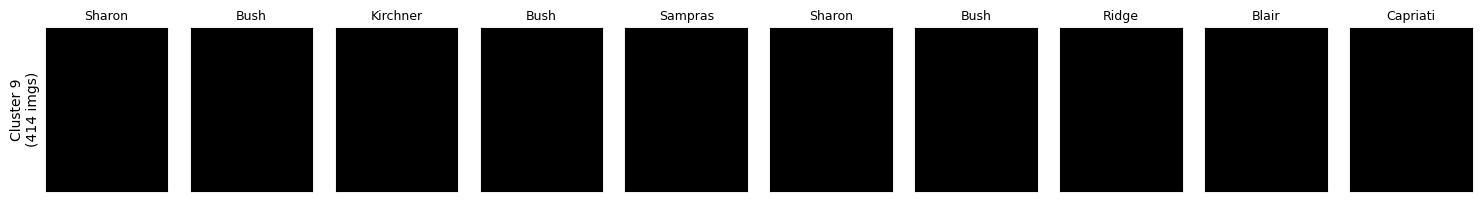

In [73]:
import matplotlib.pyplot as plt
import numpy as np

n_clusters = 10

for cluster in range(n_clusters):
    # Mask to isolate images belonging to the current cluster
    mask = labels_agg == cluster
    cluster_size = np.sum(mask)

    # Get up to the first 10 images and labels in this cluster
    cluster_images = X_people[mask][:10]
    cluster_targets = y_people[mask][:10]

    fig, axes = plt.subplots(
        1, 10, figsize=(15, 2), subplot_kw={"xticks": (), "yticks": ()}
    )

    # Label the far-left axis with the total size of the cluster
    axes[0].set_ylabel(f"Cluster {cluster}\n({cluster_size} imgs)", fontsize=10)

    # Plot available images in the cluster
    for i, ax in enumerate(axes):
        if i < len(cluster_images):
            ax.imshow(
                cluster_images[i].reshape(image_shape),
                cmap="gray",
                vmin=0,
                vmax=1,
            )
            # Display last name of ground-truth person
            last_name = people.target_names[cluster_targets[i]].split()[-1]
            ax.set_title(last_name, fontdict={"fontsize": 9})
        else:
            # Hide unused subplot axes if cluster has < 10 images
            ax.axis("off")

    plt.tight_layout()
    plt.show()

Cluster sizes: [268 151  44 129  23  63  19 101 116  13  66 102  51  40  30   2  74  44
  25  29  11  19 135  15  20  19  44  84  50  21  31   6   8   8  38  48
  19  66  27   4]


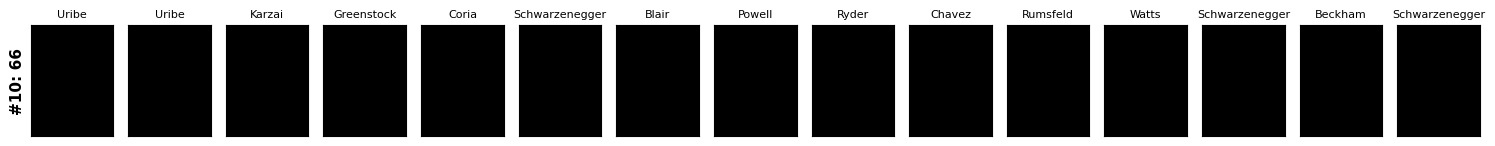

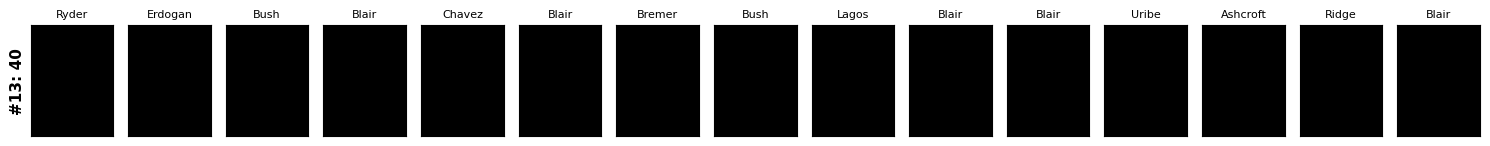

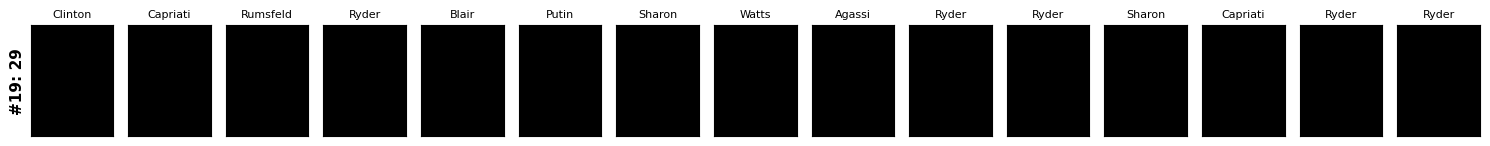

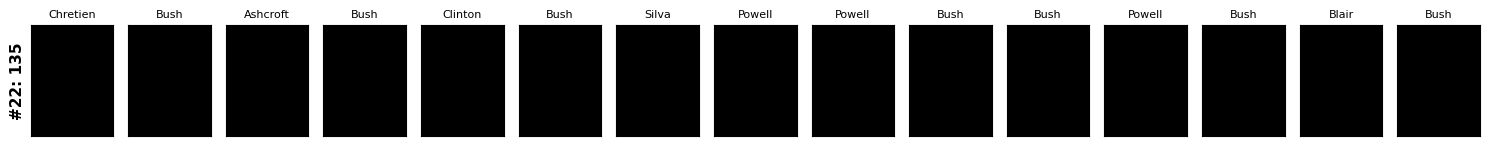

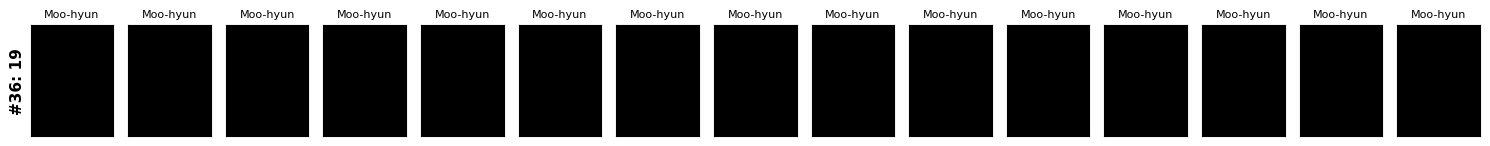

In [75]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import AgglomerativeClustering

# 1. Perform Agglomerative Clustering on PCA-reduced data
agglomerative = AgglomerativeClustering(n_clusters=40)
labels_agg = agglomerative.fit_predict(X_pca)

# Print distribution of images per cluster
print("Cluster sizes:", np.bincount(labels_agg))

# 2. Inspect specific hand-picked clusters
interesting_clusters = [10, 13, 19, 22, 36]

for cluster in interesting_clusters:
    # Boolean mask for images in the current cluster
    mask = labels_agg == cluster
    cluster_size = np.sum(mask)

    cluster_images = X_people[mask]
    cluster_targets = y_people[mask]

    fig, axes = plt.subplots(
        1, 15, figsize=(15, 2.5), subplot_kw={"xticks": (), "yticks": ()}
    )

    # Label the first axis with Cluster ID and total size
    axes[0].set_ylabel(
        f"#{cluster}: {cluster_size}", fontsize=11, fontweight="bold"
    )

    # Plot up to 15 images in the cluster
    for i, ax in enumerate(axes):
        if i < cluster_size:
            ax.imshow(
                cluster_images[i].reshape(image_shape),
                cmap="gray",
                vmin=0,
                vmax=1,
            )
            # Display person's last name
            last_name = people.target_names[cluster_targets[i]].split()[-1]
            ax.set_title(last_name, fontdict={"fontsize": 8})
        else:
            # Hide empty subplots if cluster size < 15
            ax.set_visible(False)

    plt.tight_layout()
    plt.show()